# 演習5：H₄で測定計画とGaussian更新を反復する

演習4と同じH・全0測定を使い、準備Mと発展Mを独立に選びます（既定6・16）。
本冊では、**現在の推定から次の測定を選び、測定後に推定を更新する**過程を追います。
最初に1ラウンドを段階ごとに実行し、その後、同じ処理をループで繰り返します。
ラウンド数を2に固定しません。まず5ラウンド、次に回数や初期分布・shotsを変えて比較します。

```text
事前 Gaussian(μ,v)
    ↓ μ,vから時間LΔtと探索点εを選ぶ
BPDEを各εで測定 → 全0確率または頻度
    ↓ 確率曲線をGaussianにフィット → 中心m、幅²w
事前Gaussian × フィットGaussian → 事後 Gaussian(μ',v')
    ↓ 次の事前(μ,v)へそのまま渡す
次ラウンド
```

| 段階 | コード | 各ラウンドの図 |
|---|---|---|
| 事前→測定計画 | `choose_measurement_settings` | A：事前・探索窓・探索点 |
| 測定→フィット | `meter.measure`, `fit_gaussian_signal` | B：観測とフィット、C：残差 |
| フィット→事後 | `update_gaussian_prior` | D：事前・正規化したフィット・事後 |
| 次ラウンド | `iterative_bayes` | 表の事後が次の行の事前と一致 |

著者コードのGaussianフィットとGaussian積の更新を参照します。
**演習1・2の二項尤度をそのまま使うグリッド更新とは異なる近似手順**です。
全ての問いに解答を付けています。Notebook単独で動き、最適化は再実行しません。

In [1]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"
# 実機モードのみ追加: %pip install "qiskit-ibm-runtime>=0.43,<0.44"

## IBM Quantum接続準備（実機を使う方のみ）

シミュレータのみで演習する方は、そのままスキップできます。
実機を使う方は次セルの `USE_IBM = True` に変更して実行してください。
パッケージのインストール後、本人のAPIキーと今回使うインスタンスのCRNを入力し、
表示されたバックエンド名から利用する実機を選びます。**ここではジョブを送信しません。**

APIキー作成・CRN取得の手順：接続確認ガイド（[https://github.com/QS-laboratory/IBM_handson/blob/main/docs/02_colab_connection.md](https://github.com/QS-laboratory/IBM_handson/blob/main/docs/02_colab_connection.md)）。
実習用インスタンスは **us-east** の **FTQC-HandsOn-20261109** です。
ご所属の利用枠を使う方は、今回の演習に利用できるインスタンスを指定してください。
APIキーは非表示入力し、コード本文・出力・GitHubへ貼り付けないでください。
事前確認用キーを削除した方は、新しいキーを作成してください。

後半の測定設定は最初はシミュレータです。実機を使う段階で
**`MODE = 'ibm'`、`CASE = 'both'`** に変更します（05も両方変更）。
冒頭の接続情報を引き継ぎ、`RUN_HARDWARE = False` で回路をプレビューします。
費用を確認してから `RUN_HARDWARE = True` に変更して送信します。
新しいランタイムで04・05を開いたときは、この接続準備も各冊で実行してください。

In [2]:
USE_IBM = False  # 実機を使う方のみ True に変更
IBM_SERVICE = None
IBM_INSTANCE = ''
IBM_BACKEND_NAME = ''

if USE_IBM:
    import subprocess
    import sys
    from getpass import getpass

    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q',
        'qiskit==2.4.1', 'qiskit-ibm-runtime>=0.43,<0.44',
    ])
    from qiskit_ibm_runtime import QiskitRuntimeService

    IBM_INSTANCE = input('今回使うインスタンスのCRN：').strip()
    if not IBM_INSTANCE.startswith('crn:'):
        raise ValueError('インスタンスのCRN（crn:で始まる文字列）を入力してください')
    _api_key = getpass('本人のAPIキー（非表示）：').strip()
    try:
        IBM_SERVICE = QiskitRuntimeService(
            channel='ibm_quantum_platform', token=_api_key, instance=IBM_INSTANCE,
        )
    finally:
        del _api_key

    _backend_names = sorted(b.name for b in IBM_SERVICE.backends())
    print('利用可能なバックエンド：', ', '.join(_backend_names))
    if not _backend_names:
        raise RuntimeError('利用可能な実機がありません。主催者へお知らせください')
    IBM_BACKEND_NAME = input('一覧から今回使うバックエンド名を入力：').strip()
    if IBM_BACKEND_NAME not in _backend_names:
        raise ValueError('一覧にあるバックエンド名を入力し、このセルを再実行してください')
    print('接続確認完了：', IBM_BACKEND_NAME, '（ジョブは送信していません）')
else:
    print('IBM接続準備をスキップしました。シミュレータで演習できます。')

IBM接続準備をスキップしました。シミュレータで演習できます。


In [3]:
ASSETS={'evolution_16': '...', 'evolution_32': '...', 'evolution_8': '...', 'evolution_exact': '...', 'model': '...', 'prep_4_A': '...', 'prep_4_S0': 'UUlTS0lUEQIEAQAAAAAAAAABcHEAAAAAAAAAHAAKZgAIAAAACAAAAAAAAAAAAAAAAgAAAAEAAAAAAAABDAAAAABjaXJjdWl0LTQyP/hUXcN2UzZ7fXEBAAAACAABAXEAAAAAAAAAAAAAAAAAAAABAAAAAAAAAAIAAAAAAAAAAwAAAAAAAAAEAAAAAAAAAAUAAAAAAAAABgAAAAAAAAAHAAAAAAAAAAAAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAgsWkSMZZH+PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAhlc5lBLVL3vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgcLURU+yH5PwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAABcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACBJ6UOpSmeo/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAEABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAWYAAAAAAAAACA41tmRSNwPAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIfO572NBh1z8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAABcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACG6YyU0ZvQPAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACBgtRFT7Ifm/AAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAj0rdsYGCnsvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgYLURU+yH5vwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIwJfdK+6n+D8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACEDCTmWMH+m/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACC1hXptzPQlAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIP8JOZYwf6T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACAhbBINbTvm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAjy6KhcKKHFPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAiy4sWUQ3sCwAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAACcQAAAAEABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAWYAAAAAAAAACO7oqFwoocU/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgYLURU+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgAvGwCCUSTPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIOzYBZl946T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIUn31ghOZA8AABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAg6NgFmX3jpPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAINmxoY8rNCEAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIQK7Q9I6d5r8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPshCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIBDP9Yhio5z8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIGC1EVPshCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIANqZaT5rkz8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACOhHXF4zMek/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACHyFS4vGT/2/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACBQtRFT7Ifm/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAI3kwAm3Yf6b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIwiniUNvYAsAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAhle9gLCSPRPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAIGBk+YOm4AMAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAISJkvGorqB8AABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAIIC1EVPsh+b8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAA3EAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgwbrmwbz7DvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAjIKkwq/H/5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAjebv5XFO4HQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACBgtRFT7Ifm/AAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAhLVSg18Kv2vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgMpEV4n4n7vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgA/jjE0sSXvwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACHKoPRzZFANAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIHtqleP835z8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIEY1LiP1eAsAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAA3EAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAjs/v6phCvRPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAADAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAI4X0YGqKc+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIuFRtyN2Q+78ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAiALERU+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAiIfgosZRUJwAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAiwLURU+yH5PwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIzL73TnyS9j8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIwPpdwe+69r8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIcHLME4rwCEAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAj4urZT+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAi42wZN+yEJwAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgAAAAARK4hPgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIS1UoNfCr9r8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIDKRFeJ+J+78ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIAP44xNLEl78ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAACAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAEABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAWYAAAAAAAAACNRw3U9b0QLAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAgYLURU+yH5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAg4JOjbxwgEwAAFAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFhHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACEwPChGb6QJAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAiK99NwTQ8JQAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAjwlnBvdRX6vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAicXtkd+pH7PwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIANtnbRRj8L8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACExYB9CO3/8/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACBgtRFT7Ifk/AAUAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAWEdhdGVxAAAABwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIC9liXWN/6j8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAHZgAAAAAAAAAI76AGhWjSCkAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAB3EAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAgK2WJdY3/qPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIiOkFOkLF9T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAGcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACC61kDlvoMW/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACDbTa7g3egLAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAZxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAINrWQOW+gxT8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAGcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACN5u5KfkDQnAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAig6Y78/DfnvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAgzYarx5BcKQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAFcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACKLpjvz8N+c/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAjQ8IofkXXDPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgg9b4ZlxL5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgAzsliQhyZvwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACFAn1KFvPsO/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACJj6Ayr8f/m/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACMD2+FcU7gdAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIGC1EVPsh+b8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACEtVKDXwq/a/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACAykRXififu/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACAD+OMTSxJe/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAICL9TULCM+T8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACBgtRFT7Ifk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACHAFG+AYs/a/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACLidl5jmZvm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACG7njpZwCwPAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIMiT0s7ccCUAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAdmAAAAAAAAAAhMdBz7w3/8vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAdmAAAAAAAAAAgULURU+yH5vwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAHcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACALdfj1seOk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAcABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAB2YAAAAAAAAACMrNgbkY7wLAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIe+IcpLJw0z8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAHcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACPwieozvlwJAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACHgFG+AYs/a/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIqCxEVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIFEMy5FoWCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIiC1EVPsh+T8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACIgbLzJtlPY/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACADM4ejjuva/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACP7JkD6v8AhAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAImCnrQfsh+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAItObkU/shCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIWKsXS/shCUAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACEtVKDXwq/a/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACAykRXififu/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACAD+OMTSxJe/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABgAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAhkyeg1M6/pvwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIGC1EVPsh+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIyCn8A7F+AUAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAB2YAAAAAAAAACADQ+3qY3rA/AAAA////////////////AAAAAAAAAAA=', 'prep_4_T': 'UUlTS0lUEQIEAQAAAAAAAAABcHEAAAAAAAAAHAASZgAIAAAACAAAAAAAAAAAAAAAAgAAAAEAAAAAAAAA0gAAAABjaXJjdWl0LTIxMTMtNDkyOTlAFTDqeBTUfHt9cQEAAAAIAAEBcQAAAAAAAAAAAAAAAAAAAAEAAAAAAAAAAgAAAAAAAAADAAAAAAAAAAQAAAAAAAAABQAAAAAAAAAGAAAAAAAAAAcAAAAAAAAAAAAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACD66hxEO1AJAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAEABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAgr4tDORkLpPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAjTJ+L4uk0LQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAABcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACCri0M5GQuk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAEABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAgYLURU+yH5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAisAtR1U8kAwAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAgYLURU+yH5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAhQh6UGSdv8PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgYLURU+yH5PwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIycstM9HM+r8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPsh+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACDkxvH86Iek/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACP83VByXUglAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAINTG8fzoh6T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACBgtRFT7Ifk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACPATfQ+p7fY/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAhPjBnKU7HrPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAh1hAs5sS8JQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAACcQAAAAEABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAWYAAAAAAAAACE2MGcpTses/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgcLURU+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAjC/3GU3tkHwAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIVAFi2ewW7D8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIA36ZHELZCkAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAhUAWLZ7BbsPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIIFX+vZxvCEAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIoDYyNRvzCMAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIcPmByO6+678ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACBgtRFT7IQnAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACHCms72kofY/AAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAiUlrji+CX5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgYLURU+yEJwAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAI/hPQg/zwBMAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIIC1EVPsh+T8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgB58kiAiLpvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAhKkNQyftkCwAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAFcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACGT0WaCULNE/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAhMI3OHZ/4GQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABQAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABYR2F0ZXEAAAADAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAiOkS/bMB/5PwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACNTuiuU3Q/c/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAA3EAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAjwKkH4OfXAPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAADAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAANmAAAAAAAAAAh6Wn+cI5kGwAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACOgqQfg59cA/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAA3EAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAgYLURU+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAjAwwGTHBvyPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAJxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIcOKc7XeU4T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIIzyv+dkqCkAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAhv4pztd5ThPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAJxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIWiSa1VJA878ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIiAGX8Vc2/z8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACBgtRFT7IQnAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACAA7V/cDxb2/AAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAiEWIHaEqj5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgYLURU+yH5PwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIIhOtxEG9AUAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIGC1EVPshCcAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACEjnz39v7f8/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACBgtRFT7Ifk/AAUAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAWEdhdGVxAAAABwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAInuMPNd2k6D8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAHZgAAAAAAAAAIPwZeTOjOCkAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAB3EAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAie4w813aToPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIFC1EVPsh+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIAC7qD03Jxr8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIJC1EVPsh+T8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABnEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAjGHkc3atrUvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAjE9BXilVj+vwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAGcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACEdQIVAWHcs/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABnEAAAAFAAUAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAI4JBjz4O22b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAFcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACNdczS+/Muk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACOMndrLqhwtAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAI11zNL78y6T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAFcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACBgtRFT7Ifk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACJCV1yn/S/k/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAABAAFAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFhHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACOLzSADj/Lg/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIsLY5HeLh+78ABQAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAhg3jz8mz/4vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAhQJZ9wthD4vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAgIOjqQEi0FQAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAgYLURU+yH5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAdmAAAAAAAAAAj2UypcDnUHQAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAdmAAAAAAAAAAgYLURU+yEJwAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAHcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACGyPDXSDNcU/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAcABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAB2YAAAAAAAAACIphF0cY4gDAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIZ48NdIM1xT8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAHcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACBAtRFT7Ifk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACAAHpLxaILW/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACCAtRFT7Ifm/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAZxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAI+a6C7hu9pb8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIjEK4M+TP+b8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABnEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAiWkFpZ8OKFPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAGAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAZxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIACXXyVtE+b8ABQAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABYR2F0ZXEAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAgAWYiK8pUIwAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAHZgAAAAAAAAAIFS1EVPshCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAHZgAAAAAAAAAIDq/S63N/+L8AAAD///////////////8AAAAAAAAAAA==', 'prep_6_A': '...', 'prep_6_S0': '...', 'prep_6_T': '...', 'prep_8_A': '...', 'prep_8_S0': '...', 'prep_8_T': '...', 'prep_exact_A': '...', 'prep_exact_S0': '...', 'prep_exact_T': '...'}
ASSET_DIGEST='6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3'
PROVENANCE={'catalog_sources': {'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/model.npz': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/chemistry.npz': 'e59c38ae26ec6c2f1caa697cec60c993961b4613a91a8221ca13802313a5cfca', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M4.json': 'd6ac38c4edc8ed85ad33023a15a1ae6c3544f934156e039e38e00a024e1b093f', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M4.json': '9ee861d0476271bd677a468016b0baa4b36c2f51027084d961bf4e8386a169b1', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M4_basic.qpy': 'bc10bf62afa30dfd834882e141556a653591425616b2616c3b0a3e08ea9a3bf6', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M4_basic.qpy': 'e177815ac67a3eb3dc603f434c63c2a5c63f4908e24578ba7c30d01eb4220372', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M4_state.npz': 'f6d6f040e07ebf94d69d3c07b298f42928547bed1154c8efcca6ed282e98421c', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M4_state.npz': '21c06431adcb7aee9aaa2ebbb1f11b1f8869dbf8adef0433e158dbfb9c565b99', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M6.json': 'e37936ef3080813709b8731308a7853d1c72a6b800b1744fe3bd12245495da4a', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M6.json': 'e3c595e2cbaa5bceb698ffa476769557840ad5aaf68e2a2cb8fce35d7986eb9c', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M6_basic.qpy': '9813bdca7341af0b0dc216df0b449dcbc3248f8dceeac1ff05cdbc305cf0acca', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M6_basic.qpy': '309d9ad0d20f536281a85026b8677c81f12aa4e62f501a98bd912224ac5adc31', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M8.json': '8222f1636f781e0f981c2dfaa7fd94a9f092718bb34153286d0bedfb366e6e58', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M8.json': '4fdc396e392a7dd117c3d7cd60c0052af3c5e22c73362a7f8424f044207231ab', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M8_basic.qpy': '7cec919bea5a6b992622f43c638c1ad9213b41c41250158de2ead1acb6acc6c1', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M8_basic.qpy': '779f4ba785a9119b344640f9acb05aa2b341913add6f244e93cd443c31050e9e', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M8_state.npz': '58266a3a8d62b3d07ffd75f7c0a41037576936aece981214f757f8ad05066161', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M8_state.npz': 'b2832c7a147cd3ab996078d35336f5b387e75c30c6995aa8f3fe43542e54f932', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M8/results.json': '839077c11ddc20d27a05db8927a9a04a587e6aba496b53786224b5088ff0ef86', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M8/basic.qpy': '3deaf715f68a8d1338a228cc12660b7f13eba469c0a3b3348fbb6a2caee42bb1', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M8/blocked_blocks.qpy': '1a825dd81eab53ac5389cd502c3d831a04b333d2f84cac4bf9aac8f161927077', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M16/results.json': '2961acc22b85c8d95b7b2dcb7f370e65c1a22e65ba49b87371df5c817c8d023b', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M16/blocked_blocks.qpy': '81facc07e84baf2150b80e2db99a950779728a35df3164dc4b21793fa9693b49', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M16/basic.qpy': 'f0ad06c8fcf0d58fcf87c65c7f110a0c9794e53ffb67f2785822a4d09332d7ab', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M32/results.json': '6f9a5512c44340480ef68e058311a392f3bfcdb81e8a7ca1653cdb4a71215024', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M32/basic.qpy': '9e75902153c3f473b95a78f18fff7d0c158ae5404e5070bacbed412830c27574', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M32/blocked_blocks.qpy': '0719165a38e6cc6e27c98b36f60bfa9fb930a1e582c1f15a04bfb200ad62b782'}}
CIRCUIT_CATALOG={'preparation': {4: {'keys': {'S0': 'prep_4_S0', 'T': 'prep_4_T', 'A': 'prep_4_A'}, 'reports': {'S0': {'M': 4, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'fidelity_S0': 0.7472368749138888, 'energy': -2.9017621667230182, 'variance': 0.07584233762181158, 'sector_leakage': 0.0, 'Nalpha': 2.0000000000000044, 'Nbeta': 2.0000000000000044, 'S2': 0.023472554427993807, 'total_energy': -1.7552115430630182, 'energy_error': 0.1425691029268541, 'fidelity_after_MPS': 0.9999999999999996, 'fidelity_after_basic': 0.7472368749138878, 'fidelity_to_MPS': 0.7472368749138891, 'MPS_retained_norm_squared': 0.9999999999999993, 'two_qubit_blocks': 14, 'depth_before': 5, 'depth_after': 61, 'cx': 42, 'synthesis_amplitude_error': 2.2835709022650224e-15, 'seconds': 4.461232083383948, 'optimizer_max_sweeps': 600, 'selected_start': 'previous_R2_saved', 'optimization_target': 'normalized chi-truncated MPS only'}, 'T': {'state': 'T', 'fidelity_target': 0.5350118068449305, 'M': 4, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'energy': -2.800501578518793, 'variance': 0.08377125021617877, 'sector_leakage': 0.0, 'Nalpha': 1.999999999999998, 'Nbeta': 1.999999999999998, 'S2': 1.6068485112203632, 'fidelity_T': 0.5350118068449305, 'total_energy': -1.653950954858793, 'energy_error': 0.22792473321489393, 'fidelity_after_MPS': 1.0, 'fidelity_after_basic': 0.5350118068449301, 'fidelity_to_MPS': 0.5350118068449307, 'MPS_retained_norm_squared': 1.0000000000000022, 'two_qubit_blocks': 14, 'depth_before': 5, 'depth_after': 42, 'cx': 40, 'synthesis_amplitude_error': 1.639747365667077e-15, 'seconds': 5.010353332851082, 'optimizer_max_sweeps': 600, 'selected_start': 'S0_M4', 'optimization_target': 'normalized chi-truncated MPS only', 'reused': False, 'model_sha256': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0'}}, 'fidelities': {'S0': 0.7472368749138878, 'T': 0.5350118068449301, 'S0_MPS': 0.9999999999999996, 'T_MPS': 1.0}, 'resources': {'S0': {'cx': 42, 'depth': 61, 'qubits': 8}, 'T': {'cx': 40, 'depth': 42, 'qubits': 8}, 'A': {'cx': 174, 'depth': 270, 'qubits': 9}, 'inverse': {'cx': 174, 'depth': 270, 'qubits': 9}}, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'S0': 'bc10bf62afa30dfd834882e141556a653591425616b2616c3b0a3e08ea9a3bf6', 'T': 'e177815ac67a3eb3dc603f434c63c2a5c63f4908e24578ba7c30d01eb4220372'}}, 6: {'keys': {'S0': 'prep_6_S0', 'T': 'prep_6_T', 'A': 'prep_6_A'}, 'reports': {'S0': {'M': 6, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'fidelity_S0': 0.9385998057176962, 'energy': -3.0355469148206295, 'variance': 0.004990194169048262, 'sector_leakage': 0.0, 'Nalpha': 1.9999999999999978, 'Nbeta': 1.9999999999999978, 'S2': 0.01091274695133851, 'total_energy': -1.8889962911606295, 'energy_error': 0.00878435482924278, 'fidelity_after_MPS': 0.9999999999999996, 'fidelity_after_basic': 0.938599805717698, 'fidelity_to_MPS': 0.9385998057176966, 'MPS_retained_norm_squared': 0.9999999999999993, 'two_qubit_blocks': 21, 'depth_before': 7, 'depth_after': 60, 'cx': 60, 'synthesis_amplitude_error': 2.932334201094587e-14, 'seconds': 7.219196999911219, 'optimizer_max_sweeps': 600, 'selected_start': 'previous_R2_saved', 'optimization_target': 'normalized chi-truncated MPS only'}, 'T': {'state': 'T', 'M': 6, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'energy': -3.0281037549308167, 'variance': 0.0002460447628574414, 'sector_leakage': 0.0, 'Nalpha': 2.0000000000000018, 'Nbeta': 2.0000000000000018, 'S2': 1.9995674188275885, 'fidelity_T': 0.9995639803397399, 'fidelity_target': 0.9995639803397399, 'fidelity_after_MPS': 1.0, 'fidelity_after_basic': 0.9995639803397381, 'fidelity_to_MPS': 0.9995639803397397, 'energy_error': 0.0003225568028701886, 'total_energy': -1.8815531312708167, 'MPS_retained_norm_squared': 1.0000000000000022, 'two_qubit_blocks': 21, 'depth_before': 7, 'depth_after': 62, 'cx': 60, 'synthesis_amplitude_error': 1.1053257242024359e-14, 'selected_start': 'seed3', 'optimization_target': 'normalized chi-truncated MPS only', 'reused': True, 'source': 'hands_on/self_study/h4_mps_preparation_study/results/both_states_M6_evolution_M16_L1'}}, 'fidelities': {'S0': 0.938599805717698, 'T': 0.9995639803397381, 'S0_MPS': 0.9999999999999996, 'T_MPS': 1.0}, 'resources': {'S0': {'cx': 60, 'depth': 60, 'qubits': 8}, 'T': {'cx': 60, 'depth': 62, 'qubits': 8}, 'A': {'cx': 258, 'depth': 378, 'qubits': 9}, 'inverse': {'cx': 258, 'depth': 378, 'qubits': 9}}, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'S0': '9813bdca7341af0b0dc216df0b449dcbc3248f8dceeac1ff05cdbc305cf0acca', 'T': '309d9ad0d20f536281a85026b8677c81f12aa4e62f501a98bd912224ac5adc31'}}, 8: {'keys': {'S0': 'prep_8_S0', 'T': 'prep_8_T', 'A': 'prep_8_A'}, 'reports': {'S0': {'M': 8, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'fidelity_S0': 0.9994591651078574, 'energy': -3.0438866915214646, 'variance': 0.00041835944114700807, 'sector_leakage': 0.0, 'Nalpha': 1.999999999999994, 'Nbeta': 1.999999999999994, 'S2': 0.0005563251478480163, 'total_energy': -1.8973360678614646, 'energy_error': 0.00044457812840770217, 'fidelity_after_MPS': 0.9999999999999996, 'fidelity_after_basic': 0.9994591651078605, 'fidelity_to_MPS': 0.9994591651078578, 'MPS_retained_norm_squared': 0.9999999999999993, 'two_qubit_blocks': 28, 'depth_before': 9, 'depth_after': 81, 'cx': 80, 'synthesis_amplitude_error': 8.760391339657296e-15, 'seconds': 9.110973667353392, 'optimizer_max_sweeps': 600, 'selected_start': 'previous_R2_saved', 'optimization_target': 'normalized chi-truncated MPS only'}, 'T': {'state': 'T', 'M': 8, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'energy': -3.028421618181383, 'variance': 4.2579747629443455e-06, 'sector_leakage': 0.0, 'Nalpha': 2.000000000000005, 'Nbeta': 2.000000000000005, 'S2': 1.9999921123075026, 'fidelity_T': 0.9999941418017854, 'fidelity_target': 0.9999941418017854, 'fidelity_after_MPS': 1.0, 'fidelity_after_basic': 0.9999941418017827, 'fidelity_to_MPS': 0.9999941418017854, 'energy_error': 4.69355230414692e-06, 'total_energy': -1.8818709945213827, 'MPS_retained_norm_squared': 1.0000000000000022, 'two_qubit_blocks': 28, 'depth_before': 9, 'depth_after': 82, 'cx': 80, 'synthesis_amplitude_error': 2.701678414537073e-14, 'selected_start': 'grown_T_M6', 'optimization_target': 'normalized chi-truncated MPS only', 'reused': True, 'source': 'hands_on/self_study/h4_mps_preparation_study/results/both_states_M6_M8_evolution_M32_L1'}}, 'fidelities': {'S0': 0.9994591651078605, 'T': 0.9999941418017827, 'S0_MPS': 0.9999999999999996, 'T_MPS': 1.0}, 'resources': {'S0': {'cx': 80, 'depth': 81, 'qubits': 8}, 'T': {'cx': 80, 'depth': 82, 'qubits': 8}, 'A': {'cx': 344, 'depth': 491, 'qubits': 9}, 'inverse': {'cx': 344, 'depth': 491, 'qubits': 9}}, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'S0': '7cec919bea5a6b992622f43c638c1ad9213b41c41250158de2ead1acb6acc6c1', 'T': '779f4ba785a9119b344640f9acb05aa2b341913add6f244e93cd443c31050e9e'}}, 'exact': {'keys': {'S0': 'prep_exact_S0', 'T': 'prep_exact_T', 'A': 'prep_exact_A'}, 'reports': {'S0': {'chi': None}, 'T': {'chi': None}}, 'fidelities': {'S0': 1.0, 'T': 1.0, 'S0_MPS': 1.0, 'T_MPS': 1.0}, 'resources': {'S0': {'cx': 254, 'depth': 990, 'qubits': 8}, 'T': {'cx': 254, 'depth': 1246, 'qubits': 8}, 'A': {'cx': 510, 'depth': 2490, 'qubits': 9}, 'inverse': {'cx': 510, 'depth': 2490, 'qubits': 9}}, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'method': 'exact real-amplitude Ry/CX'}}}, 'evolution': {8: {'key': 'evolution_8', 'report': {'R_angstrom': 2.0, 'M': 8, 'dt': 0.1, 'reference_cutoff': 1e-18, 'reference_sha256': '4008bee6b41dd48d0f4bf9af969cb6658eaf3f63bde7d8efd08574eca40bb95f', 'reference_path': 'hands_on/self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/reference/boys_ordered_c18_reference_adjoint.npy', 'mode_order': 'interleaved alpha/beta; blocked_blocks.qpy includes exact FSWAP conversion', 'initial_maxiter': 1500, 'refinement_cap': 10000, 'actual_refinement_iterations': 1425, 'full_convergence_claimed': False, 'two_qubit_blocks': 28, 'CX_evolution_only': 84, 'depth_before': 8, 'depth_after': 184, 'basic_operator_error': 1.0725351498587297e-13, 'mpo_error': 0.012277229834298497, 'vs_exact': 0.01227722861623843, 'S0_output_norm_squared': 1.0000000000000013, 'T_output_norm_squared': 1.0000000000000016, 'BPE_total_energy_Ha': -1.918562839198112, 'BPE_total_error_vs_FCI_Ha': -0.020782193208239708, 'native_vs_saved_blocks_max_error': 1.2700292674946032e-13}, 'resources': {'cx': 132, 'depth': 209, 'qubits': 8}, 'operator_fidelity': 0.9998492753374144, 'sources': {'basic': '3deaf715f68a8d1338a228cc12660b7f13eba469c0a3b3348fbb6a2caee42bb1', 'blocked': '1a825dd81eab53ac5389cd502c3d831a04b333d2f84cac4bf9aac8f161927077'}}, 16: {'key': 'evolution_16', 'report': {'R_angstrom': 2.0, 'M': 16, 'dt': 0.1, 'reference_cutoff': 1e-18, 'reference_sha256': '4008bee6b41dd48d0f4bf9af969cb6658eaf3f63bde7d8efd08574eca40bb95f', 'reference_path': 'hands_on/self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/reference/boys_ordered_c18_reference_adjoint.npy', 'mode_order': 'interleaved alpha/beta; blocked_blocks.qpy includes exact FSWAP conversion', 'initial_maxiter': 1500, 'refinement_cap': 10000, 'actual_refinement_iterations': 10000, 'full_convergence_claimed': False, 'two_qubit_blocks': 56, 'CX_evolution_only': 168, 'depth_before': 16, 'depth_after': 368, 'basic_operator_error': 5.621192765648292e-13, 'mpo_error': 0.0003765322575476501, 'vs_exact': 0.0003765323017011158, 'S0_output_norm_squared': 1.000000000000006, 'T_output_norm_squared': 1.0000000000000098, 'BPE_total_energy_Ha': -1.900669780380737, 'BPE_total_error_vs_FCI_Ha': -0.0028891343908648004, 'native_vs_saved_blocks_max_error': 4.648279129737457e-13}, 'resources': {'cx': 216, 'depth': 353, 'qubits': 8}, 'operator_fidelity': 0.9999998582234327, 'sources': {'basic': 'f0ad06c8fcf0d58fcf87c65c7f110a0c9794e53ffb67f2785822a4d09332d7ab', 'blocked': '81facc07e84baf2150b80e2db99a950779728a35df3164dc4b21793fa9693b49'}}, 32: {'key': 'evolution_32', 'report': {'R_angstrom': 2.0, 'M': 32, 'dt': 0.1, 'reference_cutoff': 1e-18, 'reference_sha256': '4008bee6b41dd48d0f4bf9af969cb6658eaf3f63bde7d8efd08574eca40bb95f', 'reference_path': 'hands_on/self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/reference/boys_ordered_c18_reference_adjoint.npy', 'mode_order': 'interleaved alpha/beta; blocked_blocks.qpy includes exact FSWAP conversion', 'initial_maxiter': 1500, 'refinement_cap': 10000, 'actual_refinement_iterations': 10000, 'full_convergence_claimed': False, 'two_qubit_blocks': 112, 'CX_evolution_only': 336, 'depth_before': 32, 'depth_after': 736, 'basic_operator_error': 8.398259490405766e-13, 'mpo_error': 4.4510303081657684e-05, 'vs_exact': 4.4507373016762456e-05, 'S0_output_norm_squared': 1.0000000000000095, 'T_output_norm_squared': 1.0000000000000082, 'BPE_total_energy_Ha': -1.8978224544572933, 'BPE_total_error_vs_FCI_Ha': -4.180846742096733e-05, 'native_vs_saved_blocks_max_error': 6.986790234473294e-13}, 'resources': {'cx': 384, 'depth': 641, 'qubits': 8}, 'operator_fidelity': 0.9999999980190974, 'sources': {'basic': '9e75902153c3f473b95a78f18fff7d0c158ae5404e5070bacbed412830c27574', 'blocked': '0719165a38e6cc6e27c98b36f60bfa9fb930a1e582c1f15a04bfb200ad62b782'}}, 'exact': {'key': 'evolution_exact', 'report': {'refinement_cap': None, 'full_convergence_claimed': None}, 'resources': {'qubits': 8, 'cx': None, 'depth': None, 'scope': 'dense reference; not native synthesis'}, 'operator_fidelity': 1.0, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'method': 'scipy.linalg.expm; DT=0.1; electronic H'}}}, 'pairs': {'4/8': {'digest': 'ae860acd13dc1bcbba798e133f16eae4c42eadb48d660982503b4102a421c51a', 'fringe': {'apparent_gap': 0.10785306371605936, 'Pmax': 0.9989675078496181}}, '4/16': {'digest': '69ab46cb22b2f432ab1b6ae878f8232c07a26f7cac816afda2d13be847690a5b', 'fringe': {'apparent_gap': 0.10377289921499161, 'Pmax': 0.9992030602248139}}, '4/32': {'digest': 'caac3a65d18e38897886ba7d083dac8274cfaf7271182629ba8f2b1d1b98a4fe', 'fringe': {'apparent_gap': 0.10156775408327778, 'Pmax': 0.9992025282240373}}, '4/exact': {'digest': '89ff1f57ef72a0f6202760b6780b73b5f7c1459fbcfd7e6139c35cce08e5b663', 'fringe': {'apparent_gap': 0.10129139316509635, 'Pmax': 0.999202270860379}}, '6/8': {'digest': '600ae03ef172091574d10a466e489c6c83e5447f0c2289734282426131be0b53', 'fringe': {'apparent_gap': -0.049464948673221557, 'Pmax': 0.9999349011281542}}, '6/16': {'digest': '89ec92db71f464e42d5cdd01b912ab7ecc920fa7f68f683e4addab141c337ef4', 'fringe': {'apparent_gap': 0.00922887653880968, 'Pmax': 0.9999733219281949}}, '6/32': {'digest': '786dac0328cae408d4afdec291318d15b10aa0637ef414040b1aa49d89e7ca9b', 'fringe': {'apparent_gap': 0.007402235816726176, 'Pmax': 0.9999737871606277}}, '6/exact': {'digest': 'd73a6c3ee3b118c9c1865ff74d36b3c420f644ffd1fb63ecc2c62056caa4fe92', 'fringe': {'apparent_gap': 0.007449172431888539, 'Pmax': 0.9999738327071611}}, '8/8': {'digest': '53d49f0a365080d8b7e7ff34b81a37d502b1f0b68294ed13c67a363da1325d55', 'fringe': {'apparent_gap': -0.022226569554014648, 'Pmax': 0.9999720260885926}}, '8/16': {'digest': 'dab0e031892019a951b0faddf2cf400a65d76fcd788446ee3a7f41da4cad42c7', 'fringe': {'apparent_gap': 0.01741237839140709, 'Pmax': 0.999997702264794}}, '8/32': {'digest': '3b78dab7868c2746b765f56da82af2328b82fededa3629bb3185e01647951c7f', 'fringe': {'apparent_gap': 0.015442513429593562, 'Pmax': 0.9999978538472472}}, '8/exact': {'digest': 'af39ac6444678263a61fd176ecf2b5c8f7d7340bda9a125b99692c5615613b3e', 'fringe': {'apparent_gap': 0.015465777007814745, 'Pmax': 0.9999978888936205}}, 'exact/8': {'digest': '37b703cbad22fda79d777acda354b7e5633c5a88a1e73cc6ff322fb5133d09f3', 'fringe': {'apparent_gap': -0.021787295911803166, 'Pmax': 0.9999746700754077}}, 'exact/16': {'digest': '60ad51233a9b948384eb04ef9bc528b87dae4e871c34d25270e822e77d242edb', 'fringe': {'apparent_gap': 0.017861838531962358, 'Pmax': 0.9999998822017989}}, 'exact/32': {'digest': 'c95aa63633e3c7f42d1e109797805d48310f41fe46c6ac7a6f67979d35f1aee9', 'fringe': {'apparent_gap': 0.01588830350580678, 'Pmax': 0.9999999958795622}}, 'exact/exact': {'digest': '3e62af2fe87dd2fbb355d071236b81e3731d2422fd62e3ca820d4395adf801f0', 'fringe': {'apparent_gap': 0.01590495791618658, 'Pmax': 1.0}}}, 'model_sha256': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0'}
SNAPSHOT_INDEX={'version': 'h4-pec-v1', 'dt': 0.1, 'modes': 'alpha0..3,beta0..3', 'geometry': 'linear equally spaced H4; R is adjacent distance in angstrom', 'orbitals': 'Boys + ordering; same saved coefficients per geometry', 'geometries': [{'id': 'R_0p56164086', 'R': 0.5616408602633504, 'energy_S0': -5.950151807884636, 'energy_T': -5.314827413120401, 'enuc': 4.082860435483234, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p59212035', 'R': 0.5921203495100584, 'energy_S0': -5.815850056644151, 'energy_T': -5.22746595737728, 'enuc': 3.87269454464349, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p61244001', 'R': 0.6124400090078639, 'energy_S0': -5.729368664017447, 'energy_T': -5.1700084351079845, 'enuc': 3.7442054953835586, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p66323916', 'R': 0.6632391577523774, 'energy_S0': -5.523346930619086, 'energy_T': -5.029323346352391, 'enuc': 3.457427415912824, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p73435797', 'R': 0.7343579659946964, 'energy_S0': -5.257684832765628, 'energy_T': -4.840095728689786, 'enuc': 3.122593276718893, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p78515711', 'R': 0.7851571147392099, 'energy_S0': -5.082836825812078, 'energy_T': -4.710995848139781, 'enuc': 2.920563546165731, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p81563660', 'R': 0.815636603985918, 'energy_S0': -4.983449696301517, 'energy_T': -4.636128955714771, 'enuc': 2.8114251323615074, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p88821403', 'R': 0.8882140263079715, 'energy_S0': -4.762204573403551, 'energy_T': -4.466021450897144, 'enuc': 2.5816989817777434, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p99851354', 'R': 0.9985135394661667, 'energy_S0': -4.463238569736525, 'energy_T': -4.229859148393511, 'enuc': 2.2965149261230415, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_1p04931269', 'R': 1.0493126882106802, 'energy_S0': -4.338974639816184, 'energy_T': -4.129979623344399, 'enuc': 2.1853364331563223, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_1p12043150', 'R': 1.120431496452999, 'energy_S0': -4.177742429469669, 'energy_T': -3.9991138852932813, 'enuc': 2.046623336258732, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_1p20171013', 'R': 1.201710134444221, 'energy_S0': -4.010173236576307, 'energy_T': -3.861669535566131, 'enuc': 1.9081983097201196, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p28298877', 'R': 1.2829887724354425, 'energy_S0': -3.858885352309155, 'energy_T': -3.7362913843375973, 'enuc': 1.7873120144045413, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p36426741', 'R': 1.364267410426664, 'energy_S0': -3.7225312833769464, 'energy_T': -3.622126012928441, 'enuc': 1.6808297477419407, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p55730418', 'R': 1.5573041756558155, 'energy_S0': -3.4516798470923113, 'energy_T': -3.391280928195586, 'enuc': 1.4724812808996188, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p69954179', 'R': 1.6995417921404536, 'energy_S0': -3.2930374143574537, 'energy_T': -3.2527555565497934, 'enuc': 1.3492467545808335, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_2p00000000', 'R': 2.0, 'energy_S0': -3.0443312696498723, 'energy_T': -3.028426311733687, 'enuc': 1.14655062366, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_2p26849226', 'R': 2.268492258079005, 'energy_S0': -2.89020054536246, 'energy_T': -2.8836884315667453, 'enuc': 1.0108481698155913, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_2p45136919', 'R': 2.4513691935592536, 'energy_S0': -2.808736692803678, 'energy_T': -2.8052799730776354, 'enuc': 0.9354369196385889, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_3p00000000', 'R': 3.0, 'energy_S0': -2.6316584548413777, 'energy_T': -2.6312002232856644, 'enuc': 0.76436708244, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}], 'files': {'README.md': '8d3129471983aee650e10b233630615af66ec6a1fc1070c80e41bf9219813298', 'R_0p56164086/catalog.json': 'f96365a1c3c155d7f55e670a1cfa0843ef4642949d3ae08472636fb9d515beb3', 'R_0p56164086/evolution_16.qpy': '087551b0465bdf8096fdbbc68f62889db40df52d141786e52ac7cbb764fa7c01', 'R_0p56164086/evolution_32.qpy': 'd44c7429de63daf4d5ec2a6bf1ef30f1eafeaf585d7b62b3fed3806c0e3a0c2c', 'R_0p56164086/evolution_8.qpy': '2908d963afdcfda28773c8996e1b256bed092f60071edd94dd2c9e84d3b3b4f6', 'R_0p56164086/evolution_exact.qpy': 'f1b18850e2deb9c4d60e25e8dc38a4408558dc494c7a65403ac5f4f854f967b3', 'R_0p56164086/model.npz': '39b2a7242f3e2583a5147eab082360c16acf4b908a1b3edc57c677dc181bf6cc', 'R_0p56164086/prep_4_A.qpy': 'cb1f3a6e1402355bfab0122c673a304f3cf582bb1dd41e7828f0c0b8d28b2e63', 'R_0p56164086/prep_4_S0.qpy': '223ffc313491af750f23eb7544c03699bea7b1311c873a1c61e900500866ee18', 'R_0p56164086/prep_4_T.qpy': '898d03dbd111d6a2caa610dd202a9c8635d04e8b0214048b5b68e24ebac7fed2', 'R_0p56164086/prep_6_A.qpy': '2a033e4959ce5361f60275a87690d66552ab54d8d65ed6b3e191da9c03f03ae7', 'R_0p56164086/prep_6_S0.qpy': 'd16c31dc9c892dd887b19f69baaf756e1daeb1365dab9d0328294a1c1acc8101', 'R_0p56164086/prep_6_T.qpy': '2ee6a92a898a65251ea85e1497b0cf4e4034d1c7cbfcab0cd43ddcb2016b6414', 'R_0p56164086/prep_8_A.qpy': 'dd55673437a6d032c0f5ab4e7fbe106995816a8d77aa3798ac9e8734ab8e3c1b', 'R_0p56164086/prep_8_S0.qpy': '3838d162b37a3b69b1e463465379f637db258424bf4e8d2507f3b78ceb9fbad0', 'R_0p56164086/prep_8_T.qpy': '30d5a772c7e4704257b0afb6c8e1c9b8555d0d586209fdd1603be8c6a126e85d', 'R_0p56164086/prep_exact_A.qpy': '62beae631cb91372eafe1d76e3ca265d7612e602ebc630962f19694f8433022d', 'R_0p56164086/prep_exact_S0.qpy': '0634ef8e89fe8a76b7fd8139b64f970923d8680e5ecb3874d4fd6127be6ef160', 'R_0p56164086/prep_exact_T.qpy': '8c5c093a1de2531a524124f2a24b354d1503b1529adc350a773aaa5680ab2559', 'R_0p56164086/provenance.json': '17c49ecfe406891429c0f2c367cc7748bb1c6a5866fb4c0c1d5ae9eee05107eb', 'R_0p59212035/catalog.json': '27fe3d2c4ce31cd27c23fa2005fdfb170501ba3d4b50a9ecc834926cb23fa957', 'R_0p59212035/evolution_16.qpy': '0caa046beec33c57734198bcca6cad9ff73088630a64916270f8290167c5551d', 'R_0p59212035/evolution_32.qpy': '6cc57a2b7e915791b140b1daba6b118474a8de2af876072e6df801755799207a', 'R_0p59212035/evolution_8.qpy': '4089ac0e0cd7d09669f2d243a145da3051ee4225962c6f7564108ab51b4f5be3', 'R_0p59212035/evolution_exact.qpy': 'e447096ea6f6ebaca1e43a17834af5b8ecf68fc38fa04a75654c5255d4f3c439', 'R_0p59212035/model.npz': '2c74eb77d5d20caf7642b445d2e42fa4dc4b947d9d5a752ad8601ff8170e97bf', 'R_0p59212035/prep_4_A.qpy': '5a2f5d8abd1789444d931e67211148b31adb90dee4d52737bac1156d703c4b2d', 'R_0p59212035/prep_4_S0.qpy': '7f2f0f255feb3a27bbaea76a07df2726771f2fb7b939f03671fc60367d4abfc1', 'R_0p59212035/prep_4_T.qpy': 'abece72c264b50c216f75a6a1771443596d99cf3c529cf8eff181415148553ba', 'R_0p59212035/prep_6_A.qpy': '74705b194e307f0dd96e7409545251df9f8ee8361d3adc8ee4970c28f94c2874', 'R_0p59212035/prep_6_S0.qpy': 'ed3ae782c25f7235df53403ce33dcdc7b18ca4f5336d74ef2ed1fd61d598128b', 'R_0p59212035/prep_6_T.qpy': '0d07798564b4434ee52a98cdca7dc748643e715857ce92edb32b39973089b895', 'R_0p59212035/prep_8_A.qpy': '0315ba5dd452313a5047e9e649c6f2210fe723ef241685eb3807e55cb6674171', 'R_0p59212035/prep_8_S0.qpy': 'b035829700716667327a34f84bb0bd0322732e42167434c410c59bd94384b39c', 'R_0p59212035/prep_8_T.qpy': 'eaaf3d176baba78c634de768fb9b4f347bbda278ea3ddfd9b4d3ab5428718b6c', 'R_0p59212035/prep_exact_A.qpy': 'a81c2b151461bb0d50383c409c3e8bf86aa5b3ef187b958611bbc5b41e4d8297', 'R_0p59212035/prep_exact_S0.qpy': 'e2624ef1b166634b462a7b74d7c6bc12accd51bf87b16c3695a898e0ed54a95f', 'R_0p59212035/prep_exact_T.qpy': 'f8727d06215540eda8e90a09d451bab0d5e354314ccca87b3ffab66b7acc5398', 'R_0p59212035/provenance.json': 'df50d1aef49f68558347b48d4cda58811dd65ad12d3cbcb729672bd1b642e8b7', 'R_0p61244001/catalog.json': '06720c9ee1bb173d9de0d064cb40ff24cc6edb3e24d2a0f280b2e05800f208fe', 'R_0p61244001/evolution_16.qpy': '5db25c7e9beb49c6535c38ac23ef64ae61ce82cd09ab058061a9028041e68231', 'R_0p61244001/evolution_32.qpy': '8c8c72060235d9cc3c45d0dfec62938468f9b0c808edaf61a045f0b0cda7b499', 'R_0p61244001/evolution_8.qpy': 'a4fc5dcbe4d2d79cf6d5d0b7f271dd27f429ff53aae38329a86b85ba056aac00', 'R_0p61244001/evolution_exact.qpy': 'e5e62df0c7d40ec6b8129afdeb8caaeda53451b8ba1c8cc2d03384b0c7a36373', 'R_0p61244001/model.npz': 'aa2cfc1404accf5af42aad58acf2907651a0fcbb593de7b52c100a87ae7e3bdc', 'R_0p61244001/prep_4_A.qpy': '73663bbd0b050b591889124bcbb357ea60755740898beccc19d1c49d8ed7a8bd', 'R_0p61244001/prep_4_S0.qpy': 'e6ea93ade3e6c0addc92fe3b6520daada333ff150bf7c53704986054f829b851', 'R_0p61244001/prep_4_T.qpy': '6ffe49abdbbfc60af333300e8c0c3c2d6dc62d201888bdde18b8dd1ad03f7e83', 'R_0p61244001/prep_6_A.qpy': '133530192cf71b4e5ba9ea7f205622afae424a612d5c698dcf2a67c67596362b', 'R_0p61244001/prep_6_S0.qpy': '567ded262cd6bc1627ba126eafbe4e1b54caf3e54d3b2486deca00bed7dd4b9f', 'R_0p61244001/prep_6_T.qpy': 'fa5fc7b0d7824f00f2b087d7bbb8ead71c9f3eb2537cc91c61168bb37dcb388f', 'R_0p61244001/prep_8_A.qpy': 'b14b3c7d5f954b907bc1533f9e7d8443ac397e7fb4bd1384fc9c3297a159deea', 'R_0p61244001/prep_8_S0.qpy': '3f25ccce46d6f632778d867da40110e9e22c678d35460afae25a3f84d59bfe72', 'R_0p61244001/prep_8_T.qpy': '85a36bc1f7426b4afb872cd37c7b3af36ffa3860a4f8e27dcba11d31d6c97602', 'R_0p61244001/prep_exact_A.qpy': '362d22d02fa0443982cb8f64ef25c21ac5c109551c6222dac1f5a68e03ba049e', 'R_0p61244001/prep_exact_S0.qpy': '18d175f862d68f11f9ab71daa7e771e5b250465dfeaa1d6c74d28837cf01730a', 'R_0p61244001/prep_exact_T.qpy': 'f832e3d423f5a590be851055be4f73fef6cfd54b0b717a6490206eac54595e97', 'R_0p61244001/provenance.json': 'da2d7c24c4e0bb6c7a69ba82ba03c49c7a6a7b4f312e4e930f13d42aca362e4c', 'R_0p66323916/catalog.json': '03eae60306b3969a551584c9c96cba7166c77df11e7012144f14f9c179b4ec72', 'R_0p66323916/evolution_16.qpy': '2e2ac2c8fff78cc41751e32cf8a714506089847f721320ec29fba30d720b732b', 'R_0p66323916/evolution_32.qpy': '50839443a3a1dd9e7298538f5b64079d31241a872e82e40068ea06d1e097d854', 'R_0p66323916/evolution_8.qpy': 'a167f7d41b7fca7674c95925ba44170d4ffbd150d88e7e943cc95dac7eb18698', 'R_0p66323916/evolution_exact.qpy': 'e00dafc5a79d60e6420c55c23ae3e1b762f98a947ed284357f97286f066e4978', 'R_0p66323916/model.npz': 'e38b26f7141559de504fa5b8446e840d23ca1d33f5e8c13c6e78c7ffe7419dce', 'R_0p66323916/prep_4_A.qpy': '1a15fc5d2a892a7d044c5e9b976d3dc4872dd7eb32cb09f7e314048b5f01851d', 'R_0p66323916/prep_4_S0.qpy': '649310a2dffdf3b5dd0eb6432e26dbb4de306ecc98f44b7093b91a3078c712ae', 'R_0p66323916/prep_4_T.qpy': 'f954032942a0b87cb1b9a0b5615cadbdd98081a6f9531820aa8a6d62aced9c9e', 'R_0p66323916/prep_6_A.qpy': 'fe4ef9d12e9d88cd145442b146db67db78e8764f79e80f702fbc7fa16b3f4628', 'R_0p66323916/prep_6_S0.qpy': '16a682b41299c5a8e021480689dc269be592f08d979e0f1f9c4ce59e2088e2d7', 'R_0p66323916/prep_6_T.qpy': 'eacbc2b1af2b7bb0863d8b550d7b8befc415785dcfe9d6e8abcc026052508367', 'R_0p66323916/prep_8_A.qpy': '303c6e1d0ecff8a2e89dfbd70a3f200f453dc4216b12a16f54656c00328b9c5e', 'R_0p66323916/prep_8_S0.qpy': '1f3f85ce0d90f4b8fb5044f002e5287335221cbf2f5bc9925ab3d8e429606c06', 'R_0p66323916/prep_8_T.qpy': 'b0f4e037b1f92e5547de48779836cd7cec3de391e86e91aa69e523963beb952d', 'R_0p66323916/prep_exact_A.qpy': '1d61838c636bf12111759d2c010d3fc32c64099f7dd9b90d20b15d900e8458e5', 'R_0p66323916/prep_exact_S0.qpy': '06bc2f2b2fcd36782e871c5e1a78bfbca82252e85ae2e4e0a54b838118aef060', 'R_0p66323916/prep_exact_T.qpy': 'f4a84ddb8bb69483eeeea77dbb449cb21d034c428ebc8bc962612a1b773b32e5', 'R_0p66323916/provenance.json': 'e261c5149c37bc32f147ae6447959548e4ea3831a52425c64dc8a16e8277024e', 'R_0p73435797/catalog.json': 'bf2a639c005639028e2f6f572f20c59b4d1d3bb57fb32732705feb88b0071ff0', 'R_0p73435797/evolution_16.qpy': 'a00bc56f47a42cd3faf9ebd076dc7ed4e770efa4180743aa322d7434b1d5ea16', 'R_0p73435797/evolution_32.qpy': '524821b341e0adf7f0e74fa78c77a1e0d3e1c7364538cddd1e04f770ee032349', 'R_0p73435797/evolution_8.qpy': 'bfb6a0461467d425c65e1460c2f7b8b551b07961f5e82980f472e875db69c048', 'R_0p73435797/evolution_exact.qpy': '9a6374eb7345b629e596a18214c38375c417a0663238474f4ebcda5841e684fc', 'R_0p73435797/model.npz': '6b426a456c66d84551c3cc0c8159e74052f9840ef26ba6a71b61416e9cf3cf2f', 'R_0p73435797/prep_4_A.qpy': '459f6502753deb82f2d2c5f179d60927340d03cba3b7eb70bcd9610d7620b4e7', 'R_0p73435797/prep_4_S0.qpy': '5f14b7898fd9e379fbca25bfa78b3600a1a2875e367d1cb5d0fdd2cd3568e3b4', 'R_0p73435797/prep_4_T.qpy': 'c3169d71bb4367f113b7bb11cfb81baad542e30eaba6b8241dceb1d3c454b731', 'R_0p73435797/prep_6_A.qpy': '611056b9d92000b9b1b723e942d7e7e6233def6e3f273e74bf9a89ca9059b437', 'R_0p73435797/prep_6_S0.qpy': 'c1415120a84c2d02eae7a54b9b4c0933e91b41174b3be3e877b1b4b9ce15e607', 'R_0p73435797/prep_6_T.qpy': 'b731f92f5ce613bcf943ab2573e7bd5a94cd486591eb1820bf271aa6a42a83d5', 'R_0p73435797/prep_8_A.qpy': 'fb9fca842a469d03f719e4b58649569770ea96ca029a9b722262021200351757', 'R_0p73435797/prep_8_S0.qpy': '8146f01ad32e760b7b6562fb6b2e369b6cb4b84f9fdaa2acd2b2f8cde764257c', 'R_0p73435797/prep_8_T.qpy': '1110ff4053b0a445f15cf4e4f98ce98824f249c3b538b836dd63a25163536285', 'R_0p73435797/prep_exact_A.qpy': '50895d41ae777dad8caf25cf9971bff2f2d97e7104e84d6d41efbe41caceded3', 'R_0p73435797/prep_exact_S0.qpy': '75bc1e2de3e99efe8e1ccf0d545922a50411819847b4616b363c0c8571c2a1c8', 'R_0p73435797/prep_exact_T.qpy': '83a690317cea346a33c1f8ede484b1ae07eb12840def8e1760dfff780cb4ff79', 'R_0p73435797/provenance.json': '44c5e0c72d1ba014e5312d160db204d8b57e8bc869d6cdbe9f4e82ed75a6f666', 'R_0p78515711/catalog.json': '066723daa7f81387fecee7b4ab4430a070e124e5ff1a66895475012900c986b4', 'R_0p78515711/evolution_16.qpy': 'bdeb1917fe6a409ae4b6b8b1a668cbe4851855eb94825ad584acdffcb12937b6', 'R_0p78515711/evolution_32.qpy': 'a22af3765b98cec843782b69a393ef5c763bf89219fc04afe70e2d6806b86b16', 'R_0p78515711/evolution_8.qpy': '256b77ec26bdc3c594a59155accd6271bb7467d13ed07104069820db8626a3cb', 'R_0p78515711/evolution_exact.qpy': '6f06ee603c0306e2392faf3b3bb3f2ec71e7ddc9e1853153caca2b2405adcac3', 'R_0p78515711/model.npz': 'a8f0a20f2da1e0c1ddb0c8d4702824ce0a8b37fbf400ee743a59b8863da39a4e', 'R_0p78515711/prep_4_A.qpy': 'b9e8cfd7513c028eadc38bee93482fc8a9333acee4388913c33d899b36a949bd', 'R_0p78515711/prep_4_S0.qpy': 'f5be6f4223b5e682c5b17f673b47d780c23c01e708a1d9fa471f4213d2f92b11', 'R_0p78515711/prep_4_T.qpy': '38186701cefd90fae10c23b742ba22885038141c6f6f83501f5e34b7f64a879e', 'R_0p78515711/prep_6_A.qpy': 'af6ead835da34f4e9bdc45ba868309a9b7b1d2498fea642167105c6cf308d76e', 'R_0p78515711/prep_6_S0.qpy': '254645c81d53f58e5292f446166b8975453ee1c316e2192a619fddce60969a8e', 'R_0p78515711/prep_6_T.qpy': '4b885198b58b41b7add754fdb00a4cec64111c5e12708e317c8add46acd3f526', 'R_0p78515711/prep_8_A.qpy': 'fc65a87e7307cca1b8d4bcf6378871c45f71e312624f4fc42dd1543620df1f1b', 'R_0p78515711/prep_8_S0.qpy': 'caab67505a16ffa4aff9aaa424aec7d4dafa03648850fac797a1d0b346921198', 'R_0p78515711/prep_8_T.qpy': 'c35d83abf9f9fcc214ec0f15deabcbb7ff6e4c54e3a1fa2f8ff74612e2a6f81b', 'R_0p78515711/prep_exact_A.qpy': '90aee9fa255d687c83c7cfef01bb853fe44c1166ef1a65111db4a2d0454cfb25', 'R_0p78515711/prep_exact_S0.qpy': '1f937b9b02ae64108f42a4ca674adc8aa3d55a2e560156daa12098f14c5e559c', 'R_0p78515711/prep_exact_T.qpy': 'f9c593f6273b025f08cbe74373df3b7fe8395bcf80b9ed08a764815db10122c6', 'R_0p78515711/provenance.json': '89528c3c671a1b3845429c7f9b44e5e5546cc474101b1f6f5514fe740ff9eb19', 'R_0p81563660/catalog.json': '94fe4681e8cf04e66be4bb1a7ed3a2e18095f1d191f2e1d8723238338237f8fb', 'R_0p81563660/evolution_16.qpy': '0701ccc0ed08d1707789312f89070862806602aa96223b1da74db26d7c042815', 'R_0p81563660/evolution_32.qpy': '4cf58e2102d91e4fbdf6ff7e2ecb9264007549d0da323e3745e2526445205a9e', 'R_0p81563660/evolution_8.qpy': '258c5757f0d32150fd6bbf656890dcb534fba7cc50632452a64d512d21d6e49c', 'R_0p81563660/evolution_exact.qpy': 'da0a19507e180a11dbd11b661f90e65bf274a10442b4ff5c7d5506bcf639977b', 'R_0p81563660/model.npz': '40157fadf01b6cbcbb1340829e88a534da508cf1047c6c9e51e0eeea955838fc', 'R_0p81563660/prep_4_A.qpy': 'bb790b769474f361345ff5f491e5bd4a3a00f03344b314e4fa9e56a941e7af25', 'R_0p81563660/prep_4_S0.qpy': '757b7972e77440d3946cd4b96608dbf650dd216d5652d7de00a9e15349d1e143', 'R_0p81563660/prep_4_T.qpy': '8ea591248dc0741da2712e53899b1d9dc67bdebad269a8d9365439a869224f9d', 'R_0p81563660/prep_6_A.qpy': 'e4322afec7520ab4fa1459faebcc918b1a60c7e766512260f91a445fb4ef303a', 'R_0p81563660/prep_6_S0.qpy': 'f5357bd8b6aece979b2bfcb752a86ee18c2f4c3fcea0c96bb6e2d677de27f8b6', 'R_0p81563660/prep_6_T.qpy': 'a5ed93f223b92d709a0f9d78d962d177b50caa26b563fcfa552c8e3cc1624fa7', 'R_0p81563660/prep_8_A.qpy': 'f210c8b1db5bd282f34e39e9f0ddb2e4864881c3f962be74947fa8799904be38', 'R_0p81563660/prep_8_S0.qpy': '32d5f49867988e76b97de82f71a6d68bb3ad63b655453d97f4adfadfaa672264', 'R_0p81563660/prep_8_T.qpy': '635caa83124b460d2e1a4a8ee755d56ef9b83dbc52b6a5ec01c7dc51ca31079b', 'R_0p81563660/prep_exact_A.qpy': 'bf6884c3e7242422a15046c2f6b8bc5046db1bf237d22e17ec6ce4a37b81bf77', 'R_0p81563660/prep_exact_S0.qpy': 'b70729bc404084c4139928444dca6aed5719466ba57edd854c12f7f40f2a9cbb', 'R_0p81563660/prep_exact_T.qpy': '5a3c1a06f035993f118912fb9325a6f9a0de97a8ffcfec7869595b78bfea8be4', 'R_0p81563660/provenance.json': '8f1cf4d47e1e91a7c1c3b05155f364b1cfc15f635d401ceabfb9183581858c6f', 'R_0p88821403/catalog.json': '3868ea90a8c43047a7c3d72ea6fba3098e3c61e13c7f10ddac0a898e0eb58a10', 'R_0p88821403/evolution_16.qpy': '25f8dc853e70d1f772d8b8bfe8e05074dc0cb0aab830563ab70204bed5576592', 'R_0p88821403/evolution_32.qpy': '4b95b488ee7f07ed7290688653231d17c1facfac231474c25aa58a86b0026e2d', 'R_0p88821403/evolution_8.qpy': '91db1bc270c5e85d7a5f7e5690b408ebb7122ad9aa075ef5a7f039592096085a', 'R_0p88821403/evolution_exact.qpy': 'ef5e6dfb752cae4ae230b436631a62d2654b745e75cfd4cf8da6b2e1a5b5aaa6', 'R_0p88821403/model.npz': '078396118f59b9749bb77a411f5b9cca41e0e90e4288ff1abbc6ac1cc629b0de', 'R_0p88821403/prep_4_A.qpy': '9335b8164f4c3bfb3e5e3a07e090f7b53a8eef9a7b3c990665158050a4ff00da', 'R_0p88821403/prep_4_S0.qpy': 'bc9b68b49755b1ec288c79a75b0e9e72223c6421116b59ad921dfbfe97366d1e', 'R_0p88821403/prep_4_T.qpy': '9670082bd6d125fc31ff8057a97c91dc23e60e16c547d16307e40b6b4a739e87', 'R_0p88821403/prep_6_A.qpy': '3a2f334b0137cc9a73c5b314ada4596b0da809968250062f835bc3d0d95638bf', 'R_0p88821403/prep_6_S0.qpy': '326504da7250f949aa982d6ea70f5f9e850b960a7946228d35f6da5879e60c5e', 'R_0p88821403/prep_6_T.qpy': '6c98994a284d1c03642d613861ad272d886d632a05905446f2a44d74de74fc7d', 'R_0p88821403/prep_8_A.qpy': 'bda777676960c0a14e82cdbf179cca7549919556ddab8f8292f9bd9268c66827', 'R_0p88821403/prep_8_S0.qpy': '6fb4ae3d1ab4bfd6d6910b0fab1015be0c1ff31238ff16bd49eaf09d4c8a0aa4', 'R_0p88821403/prep_8_T.qpy': '364da9aa49cca6e654ddc5c4502b86d89e8e2b19cb2c4304483f306c7b272f93', 'R_0p88821403/prep_exact_A.qpy': '77eeb3cf431fc28599cc8c7067dcebd010b6175d6866c907a1542bc68595317f', 'R_0p88821403/prep_exact_S0.qpy': '48c6fb47543490c489e47906182f758c4a368a8258318d529b20285f14077f1e', 'R_0p88821403/prep_exact_T.qpy': '929228a4ec1c9bc020ab022259b85ef170a56b552cb731080d41e194ea0f7314', 'R_0p88821403/provenance.json': 'e5bc984157d981660ff54f3c50e2eb2c39821b28a82251536afa2113bc2203a2', 'R_0p99851354/catalog.json': '2ce9b91d9173e15240cca57ea00bf08f17de76a02d6f9be78c95262c297b43b9', 'R_0p99851354/evolution_16.qpy': 'f381d2908ce1d6d185a5a704e43e08bd003f51fd456ec1ee5fc00fd5f4aeef44', 'R_0p99851354/evolution_32.qpy': '5649b23a827a85556cb5549ae6cd47d27f8ec5d8ef9a64570ade2aa9219602eb', 'R_0p99851354/evolution_8.qpy': 'e8f5dd0cd89e1407c5180c1cae04a548b654f1a624404cd1c80a10b03b579e65', 'R_0p99851354/evolution_exact.qpy': '9d45df2c3edca906b38a6a16197d29eb9449a4341ae882fba0349945b14e127c', 'R_0p99851354/model.npz': 'e83a23873e138c2447379ca0b44ee3a21305c47efc08277aa028b202b90c7246', 'R_0p99851354/prep_4_A.qpy': '003ead0caf34b6a1ec8f79857170bb2054f4334f8f7577f1a07315c24da5e16e', 'R_0p99851354/prep_4_S0.qpy': '48d900367ed4ab55e9001e157be18284f98db44f6cebbe09793f9810d154e529', 'R_0p99851354/prep_4_T.qpy': 'ea78b951dce0b1b8e1995b64b60c533c70ca4e8d2a8878ec1bb506cb8b29fc73', 'R_0p99851354/prep_6_A.qpy': '544f17a3a011da6e4286976ba433f614a3db2cdb9345aee5eb0772e59940f121', 'R_0p99851354/prep_6_S0.qpy': '04f97ce7b381b951c7524adfcd25b603b28fff33a1124652213e57a0605dd08a', 'R_0p99851354/prep_6_T.qpy': 'f73326fbc1f6250548ce00ed9d19e2bad0a3a7ee645f01310589b99767a8b4d1', 'R_0p99851354/prep_8_A.qpy': '6bf449aee954810dd334317f04ef911ee82e8facdb9ec81c77dab3cd1e3b7807', 'R_0p99851354/prep_8_S0.qpy': '4acc2715a6d977c9cfbded10b8d3e444d4e49005caa7c634783c13dbe345edd3', 'R_0p99851354/prep_8_T.qpy': 'b9a0c57de7741cb6d9811ad9421df0d2d24c81d1c8a6bdd4e781a26193cfa646', 'R_0p99851354/prep_exact_A.qpy': 'db72311abf0b645960ddd2ef26435de0ba9201edbda611b338b713b236626144', 'R_0p99851354/prep_exact_S0.qpy': '8b545bdca871b53510c66465e135ba5bdca5d890b63a68e95d1512c6e98f9977', 'R_0p99851354/prep_exact_T.qpy': '757a7a936eb90759926033126cff49d0fd56bd182e425cee3befcdb293ed8831', 'R_0p99851354/provenance.json': 'a5dfc6e436112df951a90e44939424cf1c08b5a51a8c4887291bd30fea77959a', 'R_1p04931269/catalog.json': '478c2a9c1d28fc2294d9610eef205056931212288a680aa23f7a817b04a50127', 'R_1p04931269/evolution_16.qpy': '09bffc53c9088378c8943425e52e8bfd9f0f47f732f94f9311fe524446431102', 'R_1p04931269/evolution_32.qpy': '22e47d1ac440dd0a3a7514b2f2bd0a3bd05232024acd1a37b16edf5a55632a32', 'R_1p04931269/evolution_8.qpy': '33c73c73c1bdae2c0c43423a75223a8724d43ee844a1900b1955750291c8cfea', 'R_1p04931269/evolution_exact.qpy': '8c5518252697d5aa8ec0d4b59521e18c670b49b772f778210682dd579665a972', 'R_1p04931269/model.npz': 'f155098359579204fa3a0b2a597f454d07d67991993a5f2bf611b6ee8e75a882', 'R_1p04931269/prep_4_A.qpy': 'fcaf1e67e3d08d50aa5524066079e0a2abe6f5e50ad18dac7cffd519dd8c4922', 'R_1p04931269/prep_4_S0.qpy': 'a55a9e1166c825e44319b5cc6eb673f3ad67725489d3f20832ef5aca91d49299', 'R_1p04931269/prep_4_T.qpy': '770824722e4ace72d143575aaaa5f90f908b3537b6bd9740e3d2522b0e88e68a', 'R_1p04931269/prep_6_A.qpy': 'b1fcf8699d8208a408bfe19b067377719190657cf5f2fb63b01ee7883dfae736', 'R_1p04931269/prep_6_S0.qpy': 'bc81b2bbdaeaf8c62404cd3ea59bc4be96077532c62d70edb4612ea598d1fc22', 'R_1p04931269/prep_6_T.qpy': 'b7ff4a23e4afd57cff2fe29a6028dea9c7d446fdd9eff0c2207dc05191930010', 'R_1p04931269/prep_8_A.qpy': 'ebbf3f64e543f9cb6fb9263d08384b2ae20061d70c9683970d845f36e4b17387', 'R_1p04931269/prep_8_S0.qpy': 'a5797c886a6b7ecda6cab528c7d222e63c656133c2e60d2cdc2ebaebd3bcb8c4', 'R_1p04931269/prep_8_T.qpy': 'ac5becf6d220de511b87012cd0ac3ce9967358a11b70e63a31d80a1af12f4d4c', 'R_1p04931269/prep_exact_A.qpy': '5612313e598835bc5ff372856c4f7b732fb0b1225e0da8170d3d029c8a068dee', 'R_1p04931269/prep_exact_S0.qpy': '56f9755e59fb43e559f6677c1925594a99bf86d6e5592dd0a9d2ef5968f90474', 'R_1p04931269/prep_exact_T.qpy': '7b6ed0cccf6d144a95f4aa40a41638747f2060efe5c792484124ad63e4a0e1d1', 'R_1p04931269/provenance.json': '7e0db23803aca866c231834f9e3b051e931f392038213e2752c13ae6e347a270', 'R_1p12043150/catalog.json': '8f3f779955f6e7cc74ba4898e8d98577910913c72452febe9eef1217e6c0914c', 'R_1p12043150/evolution_16.qpy': '37466bfd8e649b51d633d369e9257285b4037e7d87991a766628b8612ca09a89', 'R_1p12043150/evolution_32.qpy': '017b4638fe5cc34dd07b9fc52f3d5ea2f19c26153c9726f88db1de58de10cdaa', 'R_1p12043150/evolution_8.qpy': '99c22624b1c1f32277e525a8fcc6b8674a1ad3bbc3fefeb42a7c9be768ec85d4', 'R_1p12043150/evolution_exact.qpy': 'afbd8295a99f6034773cfd7c54ebf92b2f1fc9818638f764e680045f070f1626', 'R_1p12043150/model.npz': '54e32551725f8845531409eea42dccdf78fb971a6da11afdab33c222bb7d0e64', 'R_1p12043150/prep_4_A.qpy': '15245f83126f7417d2a10f22a9d0b0edae8c11049aab0f4820677ac50551dfbc', 'R_1p12043150/prep_4_S0.qpy': '2abd088a38685dc93153a12ba289aa037bfe37704de5faf0d1a7814e8fc9ad25', 'R_1p12043150/prep_4_T.qpy': 'db52af2a6b5f4c961436d04392f212d69ab5199bae1f92c2f24354ab30b8f63c', 'R_1p12043150/prep_6_A.qpy': '12983578d0780ae94d24b6ce9712827fe06083f7c53b192d28708c50b435d4b1', 'R_1p12043150/prep_6_S0.qpy': '71b429d62012476b20c560220a8c12af370b6459a7bac709a768be98b010a642', 'R_1p12043150/prep_6_T.qpy': 'a26be464d8aa57294001f432e1b6486ebce0ff4b2e8a7c8f8da790c03fd84b46', 'R_1p12043150/prep_8_A.qpy': '8c9c0588ba4eefb09079a0fdca08b1b608f41ee2c9eba293ba44e26ffaad8c97', 'R_1p12043150/prep_8_S0.qpy': '7f3c574fe74d91797281883f059d0a91603d1a2990a1bf57935542233857a6b0', 'R_1p12043150/prep_8_T.qpy': '6f9610875089cf62bfa8818486b83cc285ff6476556430a54b5ecb6a6ffbc333', 'R_1p12043150/prep_exact_A.qpy': '5ac5055266f9b91d6ddd3eb3b1e6b353851b47ee29492b5732c0a24a973b890e', 'R_1p12043150/prep_exact_S0.qpy': 'd5bb34e206b9f24b5beb92b58c7160614218ad43359feb64c10bdb604a9c3bc9', 'R_1p12043150/prep_exact_T.qpy': '8046e46d2c9e4dac3636e7c0f59d265652c25e61cde12b51ad214416e6f7ae43', 'R_1p12043150/provenance.json': '173f7ed11913db4c2663775616f7c0e26e6855edfc7bd612d448a60e082d723c', 'R_1p20171013/catalog.json': '3cca4a182dc396ab6410ca198e951764294bcd300fe47db527aa41fdb250fa04', 'R_1p20171013/evolution_16.qpy': 'f0210ffd2bd2006d3034ca4e8bf203d2145d57f9fa7ee790da165ee8fd754afd', 'R_1p20171013/evolution_32.qpy': '087d8fb852df491a2f99a81d43e588df52a7746b46940a16472194601cbfb790', 'R_1p20171013/evolution_8.qpy': '2a114caad8f6e488e1550f46c46d8f9afada656d5691d338bdd11de247d14152', 'R_1p20171013/evolution_exact.qpy': '385a1b0bb177470c57fbe4f61c47ff3f12e2f72acd9056234c7b6cd20f791559', 'R_1p20171013/model.npz': '8f4bab86a1601afa6888408da2c7a9e0c3cfe10a2a4c0cadfacb9f863878ca24', 'R_1p20171013/prep_4_A.qpy': 'ac1381a880b8f637fd9ff0a45e0c59cf079e24493dfb33af2901729b9df04993', 'R_1p20171013/prep_4_S0.qpy': '4c143ec47af918725cb6c8fc100d8d6cc4bc205d4cf184daf725b91262e1aa08', 'R_1p20171013/prep_4_T.qpy': '60a8e62cf029c18955bfbaf64953c9cc44c243db904429817612565ff29d306e', 'R_1p20171013/prep_6_A.qpy': '3e3129b51b04244226836da70db409e51e6d9242c5f2c45509dd96f9be3827b8', 'R_1p20171013/prep_6_S0.qpy': '0241dd75b14329db8811412eb1ac8102f50f76d6fa3e568a23e62f203b4de7d5', 'R_1p20171013/prep_6_T.qpy': '88e59c975e8552385ce9730adad118d42670faacecacc479d7f5a5faf5e3db7b', 'R_1p20171013/prep_8_A.qpy': 'eb1c0c2d89acc2949ebb965d65c1f302204890b8db218ada2836d2e8dc2c8e4a', 'R_1p20171013/prep_8_S0.qpy': 'e87f69f3f1a3fe538b551c4784cb9d1844fdfd76bc5c13888aa42cab4cdbc0ee', 'R_1p20171013/prep_8_T.qpy': '9f5d60eeabb03c06002ffc60249de9fbd3ca656576966cf6dd3d44fb810567bb', 'R_1p20171013/prep_exact_A.qpy': '374a4a4c7ee7237ff4cf1758fb1ec143e2214a14e0247e99dffc13985813d0c7', 'R_1p20171013/prep_exact_S0.qpy': 'e83f87cceddc6bfd072fb10412bc10d24d711e22af33a376323dab0fb676ed36', 'R_1p20171013/prep_exact_T.qpy': '5907728d9e2ff33b48d3944866640bd58d142eaa6044784173ce0429445404ef', 'R_1p20171013/provenance.json': 'e86eed99361cda8cb2b9a12902cf23ba66fce1addc991e3d33ad37e137a9695d', 'R_1p28298877/catalog.json': 'e5883857454e81e0f84edb0afb6f8e4bfa1e8f11716bd7041fa595a5fedbb9b7', 'R_1p28298877/evolution_16.qpy': '29bddca6c641603b8cb2ef751cff3d9d6a9c808cf533503f84a418b7943f20b0', 'R_1p28298877/evolution_32.qpy': '6760817fa387dc8b537d676a158059b51722f9b96a4fd6f1fa92a7bc79c9bcb6', 'R_1p28298877/evolution_8.qpy': '99d5aa02f8f95649747cf255b7d97c7234fa691830a34ef8707b9da8d2419fbd', 'R_1p28298877/evolution_exact.qpy': '52c476effe076a4897f34e4602b99660d1a5357bf6e3c67954a26dbe066e4339', 'R_1p28298877/model.npz': 'c45778aa5ef5079671b0125f8687b0bc8613d98457f8d49acf58503c0844c5d8', 'R_1p28298877/prep_4_A.qpy': 'e25f9600764f6fb0b5fd51ab93793b83296d6b4f18f1dfb99ed13b3b31eb0d87', 'R_1p28298877/prep_4_S0.qpy': 'f05b0bd9c87529d5a0aefaef490e6ca7ea3fd6b5d2fb5111b2095b5c0505ccfa', 'R_1p28298877/prep_4_T.qpy': '03ba93336d269f9da9b452fb77d58d15bc7cef30b8e8a43029effb5ae065eae4', 'R_1p28298877/prep_6_A.qpy': '271f7deddd23fc5bea47ab261cb671e463af49c71ea67bcfa2c49e1779f8abb0', 'R_1p28298877/prep_6_S0.qpy': '52b53c5d9cca48c9096d29c85f0574cd7c51fc1a3a76e0f3791071955b61038c', 'R_1p28298877/prep_6_T.qpy': 'e2aa663ee2f36eda6a03fb09d72239984fe75810e5feb900a707f65417a23b08', 'R_1p28298877/prep_8_A.qpy': 'cc43b0737bf259a6b22b52bd2c24488ff73d3ca5b104c33fd7e2c3005afb1ff3', 'R_1p28298877/prep_8_S0.qpy': '556f932f2a740f53f5aeb0a96b2784988253808424b3efb03041f23a5a5e4f1d', 'R_1p28298877/prep_8_T.qpy': '1f11d5499d88c7a5135584b19b91290c8ac0c8bab8a1038df056ed5dca45eba0', 'R_1p28298877/prep_exact_A.qpy': '153d23b55953518057aca11874a862b37088c383adb77841a971f189e31fbdfd', 'R_1p28298877/prep_exact_S0.qpy': '574f7048bc159514f4ef70c3c442787de570d9b69d71f4d3e57a05c320d90ae3', 'R_1p28298877/prep_exact_T.qpy': '8c4a5b1c49adddadf9ed6532ddddaee0c2432674463bdc7543daa4aed357030c', 'R_1p28298877/provenance.json': '0718153452cc85e9dabe7d39025d067d00509b1a4e5e758256af6af5e8abf399', 'R_1p36426741/catalog.json': '6117ec97a957ab36f94037986affaa6d57cdf7950b1e3010a8076316f9788de4', 'R_1p36426741/evolution_16.qpy': '8976b7bd035ab085e941818c7df8ed43c216886ce0248910c94e67ff21774074', 'R_1p36426741/evolution_32.qpy': 'e81d0830955ee072732611cde41cad4774c799ebbb57b133b1c2cd57e738055c', 'R_1p36426741/evolution_8.qpy': 'e2c142ee9a0b8589dd0a899c3a37ab6f83409baa904c6efee9547ea2ad79c0d3', 'R_1p36426741/evolution_exact.qpy': '6a0896e63e5dc0ed0c43b01b26f77f4cca6352732bda8a03930d569217d2c0c1', 'R_1p36426741/model.npz': '8c1a695105688513080b7f7048f494256343901c5514e7feb3750a308d445c96', 'R_1p36426741/prep_4_A.qpy': 'a7876d7257804658dac47889ab63c035bc8b3298ef7fbae1c2dcbaf81d031c66', 'R_1p36426741/prep_4_S0.qpy': '7db370c1a5c60fff5af8e40bb260b3a1df1203a4f145854b740031c28b74b24f', 'R_1p36426741/prep_4_T.qpy': '3c98028b1774b9831afab24621d730147489a19f6cf67336851c599de2708409', 'R_1p36426741/prep_6_A.qpy': '312de4b45b0fd16b30d0a44b35ec290a8d15714d7307dae11e24aa5f5b290652', 'R_1p36426741/prep_6_S0.qpy': '76d6069879f7399ac37d37a5e1a1025351072b4c96bf128f23e6890472a48717', 'R_1p36426741/prep_6_T.qpy': '6efd7976b7615291700d99fecfdae63459503b66ef5ef14671f8abebf5a1521e', 'R_1p36426741/prep_8_A.qpy': '3649ba06258f7b419bd7537eee92b23d4cede6f49c2dea8cf514446e851b2ff2', 'R_1p36426741/prep_8_S0.qpy': '18bf0ebb847885cd4cfdb1b2478f9cb57686dd4279dbf5901f097d2e3f207543', 'R_1p36426741/prep_8_T.qpy': 'af890492e943a4b9cbae11e8f4bf12cbf043c8decea9896c23e0f1c3bfc2572f', 'R_1p36426741/prep_exact_A.qpy': 'b2e2c9dd2f6491364912c18674ce279e24a819ad1fc3ef278214b6f42363ff26', 'R_1p36426741/prep_exact_S0.qpy': 'd527b953104ad0a40e6c2640fb0944f45416c748274549e3ccb894ac6ea940af', 'R_1p36426741/prep_exact_T.qpy': '9f4d30a368c58a423a8a0b5e37dd17264bc1106a6912aedc9f8a8281aa1b252d', 'R_1p36426741/provenance.json': '653fa960c28c5d857a6ecd43fbc7ffe5da4e52cb5746bc9ee66ec8c005bb2629', 'R_1p55730418/catalog.json': 'a1321126063224e3b09c67fda28b3deb8ea7d33d4423965fd2d75dd8098e267a', 'R_1p55730418/evolution_16.qpy': '13c98b5b8c077f96f131ae0c7755060683b398e04cc6320c071b1b6cb5c3cadd', 'R_1p55730418/evolution_32.qpy': '98d75bb0888409d0d80095b6443f6ce7231225e6f3c130dec8f91629f5f0e237', 'R_1p55730418/evolution_8.qpy': '0900504b2c50460f11a868a5df7d09afa6c9fa468a8892edec8664d11e13d843', 'R_1p55730418/evolution_exact.qpy': '68678989bc57802b9514f61ed619cd87b294266bb4602cc9f2d264cae98a5f81', 'R_1p55730418/model.npz': '6b221cead669dd3ab4f5cf2649e5b08f2627ba51db4d86f3feb50246d69444a3', 'R_1p55730418/prep_4_A.qpy': '181c8bb5fad787d9aa472c8db8556bd032603d41bee9d1fc6fbd69d64d9eea66', 'R_1p55730418/prep_4_S0.qpy': 'b6c4fb87085ac31747cda4317066c38770bacad8be9fb7de3718b0f4c720fc9d', 'R_1p55730418/prep_4_T.qpy': '7b587c1a9da9f82afc7bcc6130e5e71463adb81792d011dd4797a2a854360a92', 'R_1p55730418/prep_6_A.qpy': 'cdba3c6871c3f97c2330db03b2ec267936417fe1a5c61b3e6509447bc48212cf', 'R_1p55730418/prep_6_S0.qpy': 'ab9dc0a879c76a9fb0ceaf9df46c0d5b6d43a87a194ca53bf97a217030270859', 'R_1p55730418/prep_6_T.qpy': '62cbfbfa37aaf39abc6148896b17c92af6685700b4cc7214f245ec39f25240c1', 'R_1p55730418/prep_8_A.qpy': 'ae033fbbe42569bd2551c592867a2725470d153e3175a7781745d260a395510e', 'R_1p55730418/prep_8_S0.qpy': '075f81fa33f8315906a9313b0f5569e5d62af6911c7eb9ada35b90ded0ca2f14', 'R_1p55730418/prep_8_T.qpy': '9d4732448a54040fcb096f7f44712e3192f86e4bb1492b8252e966a2ce3b50b7', 'R_1p55730418/prep_exact_A.qpy': '1318fe71727d04753d16335247612f9e788c5ab33a455e55d35324716f37e662', 'R_1p55730418/prep_exact_S0.qpy': 'f10bf284c396aaffa990ab2675132df6509c94dacda74c18de5cf49ded215b5b', 'R_1p55730418/prep_exact_T.qpy': 'a31f82d2df7a26031593d2d2bdf7654a1189280a01c61dc04e3de3a03a3bfcf7', 'R_1p55730418/provenance.json': 'a44a63f3f6a2cb9430266a6eab19c7bcde26ba28a0bdcd33cf227057760cfe09', 'R_1p69954179/catalog.json': 'f3e9b9096ba2941885c1367b19f1599d4677f087f40eedce88111513ed8edae7', 'R_1p69954179/evolution_16.qpy': '28b58bf46428f9ad92fe8cb87b4992c345b556cf43bffdcfbc966572e6805988', 'R_1p69954179/evolution_32.qpy': '27df5c2f9bfd11a48f8ccbe1b4958d7b264fd23ad4f63805a5f04158a48cb206', 'R_1p69954179/evolution_8.qpy': '720da6044679c7b2d2847c7334350a7fcb741c89adca103470232723246a9991', 'R_1p69954179/evolution_exact.qpy': 'fe152793809692f9dbf03cf6c8d2d03a0353507795ea4ee1781d2c6b12c8559c', 'R_1p69954179/model.npz': '12c74fe63d20593c7f77e70c118c25df959a339c7d8164c2e38f016639c0ef85', 'R_1p69954179/prep_4_A.qpy': '7e2288603d26bee8d979b5078bc7daf5690a7ece72735a682cb7f198cb61b628', 'R_1p69954179/prep_4_S0.qpy': 'c9593ee9f7fecb75f7a787f21457d47da2f37d6f7843e62fe510e1a9b83897f9', 'R_1p69954179/prep_4_T.qpy': 'dfc1615837fe96ae0ef4f6856f058eedf4bc8a79cf12561460365251c9592db1', 'R_1p69954179/prep_6_A.qpy': '02098f95b334b88c2c95b2009698d27ea1ccf6c47194e6ea37520d0da370320f', 'R_1p69954179/prep_6_S0.qpy': '68a9d22762a67677b7e9c6ea37cc6183444e32ab8ad78cfa8447161bf30c21a7', 'R_1p69954179/prep_6_T.qpy': '4c7a84bdb5dc7a90a028e92791694e2b77753194a26179e2e6e1e3e773d7a331', 'R_1p69954179/prep_8_A.qpy': '6c717a761624af9200870d137e747c4016d2c640b11dcdec51ff9b04ec89448c', 'R_1p69954179/prep_8_S0.qpy': '84ba8bdef29a9ce795e12132dabb4cd28c668cbc544e6e440b145438ec241770', 'R_1p69954179/prep_8_T.qpy': 'c905aaaedac48d7281315fba1af7c92acc53e4cf10cea6e8cb562f77eb70b95e', 'R_1p69954179/prep_exact_A.qpy': '15a2c72a81f01e1d449b3bff367b4795a3fdaf7005ce98a6a0e119f8487f9ad1', 'R_1p69954179/prep_exact_S0.qpy': '9d36bbd53e5435e98f1cc75c7bd581b62f2be433a9630bd0ad78afd0b44b67bc', 'R_1p69954179/prep_exact_T.qpy': '125fe0e939578127b7a78bd9e99c93126d1317e21b786d8352c6e568d9d9c3db', 'R_1p69954179/provenance.json': '2c7a6ff36958a3e3f9a0da0fbc96cd6ad7987f490af205f9037bfb8ac2e747b4', 'R_2p00000000/catalog.json': '7c37f5dce4e6c4019f0d14c5ec7eb03fb82aee5448b86b45e6d4afaf060804e8', 'R_2p00000000/evolution_16.qpy': '8283bd2279748a82ce282712ed281d81ab7ef0a31f7e62f45b88bd7aa5d9b77e', 'R_2p00000000/evolution_32.qpy': '99b32207c512072c452aafc95ac244b691833353c96a4a7d31ac2c6f038deebe', 'R_2p00000000/evolution_8.qpy': '337d8273ac35d75c4e86769d0a94f6d18b4e681c39de29d4ac2e2056b8df47af', 'R_2p00000000/evolution_exact.qpy': '6b0fbc2df2ee2bd14f69a5acd73866f44ff49a6a37310943b4faed0559887a7b', 'R_2p00000000/model.npz': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'R_2p00000000/prep_4_A.qpy': 'e19e9443554cd7226c162c5853fe4b21f5819e2f136a15b7a3bce98eaddd72bb', 'R_2p00000000/prep_4_S0.qpy': 'bc10bf62afa30dfd834882e141556a653591425616b2616c3b0a3e08ea9a3bf6', 'R_2p00000000/prep_4_T.qpy': 'e177815ac67a3eb3dc603f434c63c2a5c63f4908e24578ba7c30d01eb4220372', 'R_2p00000000/prep_6_A.qpy': 'ea52dfd25deedf9cb793f1c0ad331fa1a453def05f1504e0c94cdf21af8e7b7b', 'R_2p00000000/prep_6_S0.qpy': '9813bdca7341af0b0dc216df0b449dcbc3248f8dceeac1ff05cdbc305cf0acca', 'R_2p00000000/prep_6_T.qpy': '309d9ad0d20f536281a85026b8677c81f12aa4e62f501a98bd912224ac5adc31', 'R_2p00000000/prep_8_A.qpy': '7dc3aa91ecffca0903108736efb0a2d40ce5151a6793ed7ddb3c76933a176390', 'R_2p00000000/prep_8_S0.qpy': '7cec919bea5a6b992622f43c638c1ad9213b41c41250158de2ead1acb6acc6c1', 'R_2p00000000/prep_8_T.qpy': '779f4ba785a9119b344640f9acb05aa2b341913add6f244e93cd443c31050e9e', 'R_2p00000000/prep_exact_A.qpy': '385ba357d2423c7486644d637a17baf3f35d17b0e5fba0f0841d67e32dae963a', 'R_2p00000000/prep_exact_S0.qpy': '5f6803bceea116ce34aa80dc51a9da3628d916136187a8e436fbb7eda514b194', 'R_2p00000000/prep_exact_T.qpy': 'f1f275bac8f78a40fcaa713805eee5bf27ea9e4a9da97459c1f9b11097e13ac2', 'R_2p00000000/provenance.json': 'da61f99bdae6e24a4eff1cfd4fb98307f1ba7b39f19648e43aec70da0f193e66', 'R_2p26849226/catalog.json': 'e13f3d8432c99dfcbac93c90e4342f4201f10c222f4828586135dd6742ae1a68', 'R_2p26849226/evolution_16.qpy': '0f0f5b20155731d14b9f35fee4358016408993166f052abdc76a0464fbf68a33', 'R_2p26849226/evolution_32.qpy': 'eed1a33c5e471828b96a5fce2ba67dcf80099f7566dde8c06bbb7f1a6e27c50c', 'R_2p26849226/evolution_8.qpy': 'af8e38133d76ecdbb3b3d96da07571d9cd51b6f658c3e76428849c0069e2b9c4', 'R_2p26849226/evolution_exact.qpy': '4bf601172529792b1b3096c4f069f24df20910fb89e43798f3744f481fcedbf9', 'R_2p26849226/model.npz': 'b7923a223d2e21314a30eacb39623cac3c3f02d1467a20a509b55d6f233ba897', 'R_2p26849226/prep_4_A.qpy': '40b4eabfa175dca9ac2f342286df9ff2d96d98e8ffc1fcb00add1ae75e6d8a49', 'R_2p26849226/prep_4_S0.qpy': '273e587cb44f4e32b90753cd2eb4b8c93ffefbe8a7ec48838bee0b642c0f2fa7', 'R_2p26849226/prep_4_T.qpy': 'ec2c32dc1edb1184b3c8fa8ec17764a6b94ffb1e6a790a96e7fae6b5208501b8', 'R_2p26849226/prep_6_A.qpy': '1434cdc65051b87772124aa445a2c53db0daba7f81bac5d31012d0676163e23f', 'R_2p26849226/prep_6_S0.qpy': '848fe24ce97648ff9b9c4d40f1e1ad80c0f6147a6cc97749f5d525f164878165', 'R_2p26849226/prep_6_T.qpy': 'a34c2f1733c4ab1139dafba8dcf63288dd61407082053431962f64392ca7c659', 'R_2p26849226/prep_8_A.qpy': 'b8768724c1b9ad52261af50aeea091482a33089824b5b4815b315966a21cd0cf', 'R_2p26849226/prep_8_S0.qpy': '49350565343525eedfd226f0b22544c7a6f680b02f2dbe71d61fb9f00ee51375', 'R_2p26849226/prep_8_T.qpy': 'b962ef40b2b63ede2b5c0a42b5908a0a8c5fdfdde56652c3233332ae68d22aff', 'R_2p26849226/prep_exact_A.qpy': 'fb780cf4725582a77a9ac0b617d80f0dff35bbf6632e89b185be26cc2c30efb0', 'R_2p26849226/prep_exact_S0.qpy': 'f3c9c8b643af3a80fbd232f8bb208d9764f4bb0ecfc283de95e3c6049d1c55fe', 'R_2p26849226/prep_exact_T.qpy': 'c825687191ddd07382d3ac76d421b0ab2140bb31fee089d2499c502c37e67e8e', 'R_2p26849226/provenance.json': 'a6ed733339f48934b0321a924bdd75263a6b0f5977c569c19664f72f9fbc5f62', 'R_2p45136919/catalog.json': '3442745a2b966c46dcf21a98c0dfc2a0199ccb47b652a0abc5b44bde9aa081e8', 'R_2p45136919/evolution_16.qpy': 'fce13449adc93b2f64724a32d7e86fdd9f1a0d3d378b8f03bfdb6a10ab8ad984', 'R_2p45136919/evolution_32.qpy': '109f899989a9de6f13a6276ddd8d9f9fdf9d42fb4fc34a175d24d679c8ba06ed', 'R_2p45136919/evolution_8.qpy': 'eec05ae930dc1d60fcdf5dee83a9a5ba54806a9116667f0678ec995cd7fa4ffc', 'R_2p45136919/evolution_exact.qpy': '12cc7ac1003045bb447cd0af3d3c67fa2e53e3f100ac0ee291afe7a7c42aec2a', 'R_2p45136919/model.npz': '1434202eb13f1d3829201f0cbe6e35818cb3855867a0505d6b7e4bedc24a4cf1', 'R_2p45136919/prep_4_A.qpy': 'da2e96428ef956f40e6d063dac6b25c08c19a04a49585f59ac4b168d2ee13ae5', 'R_2p45136919/prep_4_S0.qpy': '8d8eb8c8526569fea978538b56eec727c5634b76bb81e6dd320320883844a9fd', 'R_2p45136919/prep_4_T.qpy': 'c42fd1e6d72998372f5e1f718c9ec5e41ee724fc6857a3a403a3abf176f4ea28', 'R_2p45136919/prep_6_A.qpy': '54d75c60b55eedc43e20b35f9088bbf1c16f2a8229e31cba42bfd55658dcd01b', 'R_2p45136919/prep_6_S0.qpy': '00b23ccc291ea2118fbad9bf411f30daef8488f32ec667718a3a010922dbe6d1', 'R_2p45136919/prep_6_T.qpy': 'cdb1f8eff2696d11b65353a689782cb555a6c82234f6875647858c974c5c0067', 'R_2p45136919/prep_8_A.qpy': '6a4a55cf7ebb58761a3102791b8425c9bfb912082e23f8d757464fd5651ac9ed', 'R_2p45136919/prep_8_S0.qpy': '4c5c8871261a4f4887abaa284459a8a312c3be6ed7e595cc6c78a5a92e52d5d5', 'R_2p45136919/prep_8_T.qpy': '6c521cd51e4ba6823bef06536182b0214128e32808750d2d27f4ac15bc415c71', 'R_2p45136919/prep_exact_A.qpy': '2ce0b61488b47476b1b6d153edd9ec350e842c767d65ce794408c17a44ce37c7', 'R_2p45136919/prep_exact_S0.qpy': 'f3bda680c41434efb3cf7a4e456f740aecaa97b794ebd9eebb2ea545eaaaee90', 'R_2p45136919/prep_exact_T.qpy': '803b582c920f9bb812b5c0006fa26b9e0df873a3d9b9fd80a51e375ea43494e8', 'R_2p45136919/provenance.json': '43e65b8ea1d8c5cc7b6e8c84d84ff4d13c78101c107d4c0ae9b422571571580b', 'R_3p00000000/catalog.json': 'f7774c987748a730e7f6aff841e4306995a0446bbec2c21036146e6c451ca4c5', 'R_3p00000000/evolution_16.qpy': '4394af1e9c592e31a1521aa8f094a4f9405ff5bf2c78e3d505c97db108325e80', 'R_3p00000000/evolution_32.qpy': 'a61a9b2e2c4c97934d888f266f23a9861a8b2dfa58bdeac571b0cb76936b3ff4', 'R_3p00000000/evolution_8.qpy': 'f708d821bb1c529b1e31544e7256a0cba72502d83537c4c41908b060d6584fa4', 'R_3p00000000/evolution_exact.qpy': '052f767b514fc00dbe1090c571814d851cdf14e9a42e9dd4c5a0da618535b44c', 'R_3p00000000/model.npz': 'b579cb6df9d4e63f3853c72ac8d53405afa7713c9932ea796f415f9af3dfe0d4', 'R_3p00000000/prep_4_A.qpy': '1ff739894d609764931b7cb99a14e05dcaedea0a550006ad0ac5db41f7a3173a', 'R_3p00000000/prep_4_S0.qpy': 'e1c3103458422a65b4624bcdd1bfd560fc1866c09bc1e4a893f11cf58cbc2b7c', 'R_3p00000000/prep_4_T.qpy': 'db0733a4db2f7b65f4a36592e1b24428262315b782c86321e78fa6857b47e939', 'R_3p00000000/prep_6_A.qpy': '5a77fb5ec03e5cfa9226b6c2eb96df62dd3f9c2215a51f260f931b4b035a5dff', 'R_3p00000000/prep_6_S0.qpy': 'f7698e37ff1875e59bf20af670f69cb54756a03e128b21c69be5b5fae2e13266', 'R_3p00000000/prep_6_T.qpy': 'd85e5dd39ea9ff2c7a1d20a2e4cf517fd7b02b110533901ffc657c77a1570cf6', 'R_3p00000000/prep_8_A.qpy': '289f2b9951ed5a8f7844ef0fc6f20ecdc6cc714f8c9ba3d256595c5d3a6ca21c', 'R_3p00000000/prep_8_S0.qpy': '3bd59ac943fe8094efe845408002648f9f2f3edbfaca9c146cf9f664c21befd6', 'R_3p00000000/prep_8_T.qpy': '6be8e8da3bbbeb11996622c1ad5f342d34f781fcb58a6faac9dbec028bcb4eda', 'R_3p00000000/prep_exact_A.qpy': 'dad3cf316641eb68bd7d55774169a36abfc363bf5088750049f2ee3b6ee4d9f8', 'R_3p00000000/prep_exact_S0.qpy': 'f0ba8ade4098d2b8a516d823a4336ef8b2b2cc6e44be58f08b7592c09dfd34f8', 'R_3p00000000/prep_exact_T.qpy': '1a16e226b9819903bc5d5a4b2d4003b15fd605adcc027910dc45d69a94a0a32e', 'R_3p00000000/provenance.json': '5df6e0ae88a6b79850fe5829d2502e3d88999ddc218d5a09f4a631cce0fdf6ff', 'UPSTREAM_LICENSE': '9ccf26cfe845e0eb8bb58053e47366e7ab6b697ae010f7650978d4b71b7d1fc1', 'exact_preparation.py': '03701f86f02e82918f05219e1b2aedc6bc9d069ebb8ccd4cc391bcfb720a06d2'}, 'exporter_sha256': '82fe6c0ce76db6cc27c7e032d59fb2d10bc37ff3de059ad93819fd123146b89d', 'catalog_builder_sha256': '9c2d536ab0ba21780fa6512e7ea0a26daf85ab8203c77c9d1c64622cc6f180ba', 'exact_helpers_source_sha256': '7b39e4dead1d78e9c15dc6c9ba62e48a3cc42e72d303cba3b0c618e3ad34ae69'}
SNAPSHOT_DIGEST='6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3'
"""Standalone H4 teaching runtime; no file access, optimization, or accounts.

Blocked spin order alpha0..3,beta0..3; little endian; BPDE ancilla q8.
All circuit builders return unmeasured unitary circuits for exact verification.
"""
import numpy as np
from scipy.linalg import eigh
from scipy.sparse import csr_matrix
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UCRYGate, UnitaryGate, PauliEvolutionGate
from qiskit.quantum_info import Operator, Statevector, SparsePauliOp

DT = 0.1
TAU = 2*np.pi


def fock_permutation():
    """Interleaved -> blocked: signed fermionic permutation, not bit swaps."""
    mapping = [0,4,1,5,2,6,3,7]
    indices, signs = [], []
    for n in range(256):
        occupied = [mapping[p] for p in range(8) if n >> p & 1]
        indices.append(sum(1 << p for p in occupied))
        inversions = sum(a > b for j,a in enumerate(occupied) for b in occupied[j+1:])
        signs.append((-1)**inversions)
    return np.asarray(indices), np.asarray(signs)


def to_blocked(matrix):
    indices, signs = fock_permutation()
    out = np.empty_like(matrix)
    out[np.ix_(indices,indices)] = signs[:,None]*matrix*signs[None,:]
    return out


def fermion_operators():
    operators = []
    for p in range(8):
        columns = [n for n in range(256) if n >> p & 1]
        rows = [n ^ (1 << p) for n in columns]
        values = [(-1)**((n & ((1 << p)-1)).bit_count()) for n in columns]
        operators.append(csr_matrix((values,(rows,columns)),shape=(256,256)))
    return operators


def hamiltonian_from_integrals(h1, eri):
    """Chemist ERI (pq|rs); independent explicit fermionic construction."""
    a = fermion_operators()
    h = csr_matrix((256,256),dtype=float)
    for p in range(4):
        for q in range(4):
            for sigma in range(2):
                h += h1[p,q]*(a[p+4*sigma].T@a[q+4*sigma])
            for r in range(4):
                for s in range(4):
                    if abs(eri[p,q,r,s]) < 1e-15:
                        continue
                    for sigma in range(2):
                        for tau in range(2):
                            h += .5*eri[p,q,r,s]*(a[p+4*sigma].T@a[r+4*tau].T@a[s+4*tau]@a[q+4*sigma])
    return h.toarray()


def spin_operators():
    a = fermion_operators()
    na = sum(x.T@x for x in a[:4]).toarray()
    nb = sum(x.T@x for x in a[4:]).toarray()
    sz = (na-nb)/2
    plus = sum(a[p].T@a[p+4] for p in range(4)).toarray()
    s2 = sz@sz + (plus@plus.T+plus.T@plus)/2
    return na, nb, s2


def solve_states(h):
    """Resolve spin first, then energy. T denotes lowest S=1, Ms=0 state."""
    sector = np.array([n for n in range(256)
                       if (n & 15).bit_count()==2 and (n >> 4).bit_count()==2])
    na,nb,s2 = spin_operators()
    spins, vectors = eigh(s2[np.ix_(sector,sector)])
    states, energies = {}, {}
    for prefix, spin, count in [('S',0,2),('T',2,1)]:
        basis = vectors[:,abs(spins-spin)<1e-8]
        e,v = eigh(basis.T@h[np.ix_(sector,sector)]@basis)
        for j in range(count):
            name = prefix+str(j) if prefix=='S' else 'T'
            psi = np.zeros(256)
            psi[sector] = basis@v[:,j]
            psi *= np.sign(psi[np.argmax(abs(psi))])
            states[name], energies[name] = psi,float(e[j])
    hf = np.zeros(256); hf[51] = 1  # q0,q1,q4,q5 occupied
    states['HF'] = hf
    return states, energies, (na,nb,s2)


def rotation_angles(vector, target):
    """Binary-tree real-amplitude preparation; signs retained at leaf level."""
    groups = np.asarray(vector,float).reshape(-1,2,2**target)
    if target == 0:
        left,right = groups[:,0,0], groups[:,1,0]
    else:
        left,right = np.linalg.norm(groups[:,0],axis=1),np.linalg.norm(groups[:,1],axis=1)
    return (2*np.arctan2(right,left)).tolist()


def prepare_real(vector, name='prep'):
    vector = np.asarray(vector)
    if np.max(abs(vector.imag)) > 1e-12 or not np.isclose(np.linalg.norm(vector),1):
        raise ValueError('Expected normalized real amplitudes')
    n = int(np.log2(len(vector)))
    qc = QuantumCircuit(n,name=name)
    for target in reversed(range(n)):
        angles = rotation_angles(vector.real,target)
        if target==n-1:
            qc.ry(angles[0],target)
        else:
            qc.append(UCRYGate(angles),[target]+list(range(target+1,n)))
    return qc


def prepare_pair(ground, excited):
    """A = diag(U0,Uj) (H_a tensor I); coherent branch phase is fixed."""
    qc = QuantumCircuit(9,name='A_0j')
    qc.h(8)
    for target in reversed(range(8)):
        angles = rotation_angles(ground,target)+rotation_angles(excited,target)
        qc.append(UCRYGate(angles),[target]+list(range(target+1,8))+[8])
    return qc



"""Embedded runtime for exercises 4/5. ASSETS is supplied by the builder."""
import base64
import hashlib
import io
import json
import os
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, eigh
from scipy.optimize import curve_fit, OptimizeWarning
from qiskit import QuantumCircuit, qpy, transpile
from qiskit.quantum_info import Operator, Statevector, SparsePauliOp
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import SuzukiTrotter

DT = .1

def load_array_asset(name):
    return np.load(io.BytesIO(base64.b64decode(ASSETS[name])), allow_pickle=False)

def load_circuit_asset(name):
    key = globals().get('ACTIVE_ASSET_KEYS', {}).get(name, name)
    return qpy.load(io.BytesIO(base64.b64decode(ASSETS[key])))[0]

with load_array_asset('model') as saved:
    MODEL = {k: saved[k].copy() for k in saved.files}
H = MODEL['hamiltonian']
GAP = float(MODEL['energy_T'] - MODEL['energy_S0'])
EXACT_STATES = [MODEL['S0'], MODEL['T']]
U_EXACT = expm(-1j * H * DT)
A_EXACT = prepare_pair(*EXACT_STATES)
SELECTED_GEOMETRY = 'R_2p00000000'
AVAILABLE_PREP_M = (4,6,8)
AVAILABLE_EVOLUTION_M = (8,16,32)


def select_circuits(prep_m=6, evolution_m=16):
    """Select compatible saved circuits. Rerun following cells after changing M."""
    global SELECTED_PREP_M, SELECTED_EVOLUTION_M, ACTIVE_ASSET_KEYS
    global PREP_INFO, EVOLUTION_INFO, SELECTED_RESULTS, CIRCUIT_DIGEST, SERIAL_CX
    global A_APPROX, EVOLUTION_APPROX, U_APPROX, APPROX_STATES, CASES, SPECTRA
    for value, choices, name in [(prep_m, AVAILABLE_PREP_M, 'PREP_M'),
                                  (evolution_m, AVAILABLE_EVOLUTION_M, 'EVOLUTION_M')]:
        if value != 'exact' and (not isinstance(value, (int, np.integer)) or isinstance(value, (bool, np.bool_))
                or value not in choices):
            raise ValueError(f'{name} must be exact or one of {choices}; received {value!r}')
    prep = CIRCUIT_CATALOG['preparation'][prep_m]
    evo = CIRCUIT_CATALOG['evolution'][evolution_m]
    pair = CIRCUIT_CATALOG['pairs'][f'{prep_m}/{evolution_m}']
    keys = dict(prep['keys'], evolution=evo['key'])
    circuits = {k:qpy.load(io.BytesIO(base64.b64decode(ASSETS[v])))[0] for k,v in keys.items()}
    states = [Statevector.from_instruction(circuits[k]).data for k in ['S0','T']]
    uapp = Operator(circuits['evolution']).data
    cases = {'exact':(EXACT_STATES,U_EXACT), 'prep_only':(states,U_EXACT),
             'evolution_only':(EXACT_STATES,uapp), 'both':(states,uapp)}
    # Hermitian phase decomposition accelerates U^L classically; circuits repeat L times.
    spectra = {}
    for label, (_, u) in cases.items():
        assert np.linalg.norm(u.conj().T@u-np.eye(256)) < 1e-9
        assert np.min(np.linalg.eigvalsh((u+u.conj().T)/2)) > 0
        _, vectors = eigh((u-u.conj().T)/(2j))
        phases = np.angle(np.diag(vectors.conj().T@u@vectors))
        np.testing.assert_allclose((vectors*np.exp(1j*phases))@vectors.conj().T,u,atol=1e-10)
        spectra[label] = (phases, vectors)
    SELECTED_PREP_M, SELECTED_EVOLUTION_M = prep_m, evolution_m
    ACTIVE_ASSET_KEYS = keys
    PREP_INFO, EVOLUTION_INFO = prep, evo
    SELECTED_RESULTS = dict(fidelities=prep['fidelities'], fringe=pair['fringe'])
    PROVENANCE['results'] = SELECTED_RESULTS  # legacy teaching diagnostics
    CIRCUIT_DIGEST = pair['digest']
    SERIAL_CX = dict(preparation=prep['resources']['A']['cx']+prep['resources']['inverse']['cx'],
                     evolution=evo['resources']['cx'])
    A_APPROX, EVOLUTION_APPROX = circuits['A'], circuits['evolution']
    APPROX_STATES, U_APPROX, CASES, SPECTRA = states, uapp, cases, spectra
    cost = ('native evolution CX not synthesized (dense exact reference)' if SERIAL_CX['evolution'] is None
            else f"serial CX = {SERIAL_CX['preparation']} + {SERIAL_CX['evolution']} L")
    print(f'{SELECTED_GEOMETRY}: PREP_M={prep_m} (S0/T), EVOLUTION_M={evolution_m}; {cost}')


select_circuits()

def probability(case, L, trial_gaps):
    if not isinstance(L, (int, np.integer)) or isinstance(L, (bool, np.bool_)) or L < 1:
        raise ValueError('L must be a positive integer')
    states, _ = CASES[case]
    phases, vectors = SPECTRA[case]
    amplitudes = [np.sum(abs(vectors.conj().T @ psi)**2 * np.exp(1j*phases*L)) for psi in states]
    return np.clip(abs(amplitudes[0] + np.exp(1j*np.asarray(trial_gaps)*L*DT)*amplitudes[1])**2 / 4, 0, 1)

def experiment_circuit(L, trial_gap):
    """Selected C-readout circuit; no controlled evolution or dense U^L shortcut."""
    if not isinstance(L, (int, np.integer)) or isinstance(L, (bool, np.bool_)) or L < 1:
        raise ValueError('L must be a positive integer')
    qc = QuantumCircuit(9)
    qc.compose(A_APPROX, inplace=True)
    for _ in range(int(L)):
        qc.compose(EVOLUTION_APPROX, range(8), inplace=True)
    qc.p(float(trial_gap)*L*DT, 8)
    qc.compose(A_APPROX.inverse(), inplace=True)
    return qc

def connect_ibm(backend_name, instance=''):
    prepared = globals().get('IBM_SERVICE')
    if prepared is not None and instance == globals().get('IBM_INSTANCE'):
        return prepared, prepared.backend(backend_name)
    from getpass import getpass
    from qiskit_ibm_runtime import QiskitRuntimeService
    token = os.environ.get('IBM_QUANTUM_API_KEY')
    if not token:
        try:
            from google.colab import userdata
            token = userdata.get('IBM_QUANTUM_API_KEY')
        except Exception:
            token = None
    if not token:
        token = getpass('IBM Quantum API key (非表示): ')
    kwargs = dict(channel='ibm_quantum_platform', token=token)
    if instance:
        kwargs['instance'] = instance
    service = QiskitRuntimeService(**kwargs)
    return service, service.backend(backend_name)

def hardware_preview(backend, L=1):
    if SELECTED_EVOLUTION_M == 'exact':
        raise ValueError('Dense exact evolution is a simulation reference; select EVOLUTION_M=8/16/32 for IBM')
    qc = experiment_circuit(L, GAP)
    qc.measure_all()
    isa = transpile(qc, backend=backend, optimization_level=1, seed_transpiler=7)
    report = {'geometry': SELECTED_GEOMETRY, 'prep_m': SELECTED_PREP_M, 'evolution_m': SELECTED_EVOLUTION_M, 'backend': backend.name, 'L': L, 'depth': isa.depth(),
              'two_qubit_gates': sum(i.operation.num_qubits == 2 for i in isa.data),
              'operations': dict(isa.count_ops())}
    print(report)
    return report

class Measurement:
    """One interface; hardware jobs and counts are persisted before the next iteration."""
    def __init__(self, mode='exact', shots=1024, seed=42, service=None, backend=None,
                 run_hardware=False, max_hardware_L=8, directory='outputs/ibm_jobs'):
        if mode not in ['exact', 'shots', 'ibm']:
            raise ValueError('MODE must be exact, shots, or ibm')
        if mode != 'exact' and (not isinstance(shots, int) or isinstance(shots, bool) or shots < 1):
            raise ValueError('SHOTS must be a positive integer')
        self.mode, self.shots = mode, shots
        self.rng = np.random.default_rng(seed)
        self.service, self.backend = service, backend
        self.run_hardware, self.max_hardware_L = run_hardware, max_hardware_L
        self.directory = Path(directory)
        self.records = []
        self.selection = dict(geometry=SELECTED_GEOMETRY, prep_m=SELECTED_PREP_M, evolution_m=SELECTED_EVOLUTION_M,
                              circuit_digest=CIRCUIT_DIGEST)

    def measure(self, case, L, trial_gaps, label):
        if self.selection['circuit_digest'] != CIRCUIT_DIGEST:
            raise ValueError('Circuit selection changed; recreate Measurement by rerunning the mode setting cell')
        if case not in CASES:
            raise ValueError(f'Unknown CASE: {case}')
        if not isinstance(L, (int, np.integer)) or isinstance(L, (bool, np.bool_)) or L < 1:
            raise ValueError('L must be a positive integer')
        trial_gaps = np.asarray(trial_gaps, dtype=float)
        if trial_gaps.ndim != 1 or trial_gaps.size == 0 or not np.all(np.isfinite(trial_gaps)):
            raise ValueError('trial_gaps must be a nonempty finite one-dimensional array')
        if self.mode != 'ibm':
            p = probability(case, L, trial_gaps)
            counts = None if self.mode == 'exact' else self.rng.binomial(self.shots, p)
            values = p if counts is None else counts/self.shots
            self.records.append(dict(source='exact_probabilities' if counts is None else 'simulated_counts',
                label=label, case=case, L=int(L), **self.selection, trial_gaps=trial_gaps.tolist(),
                shots=None if counts is None else self.shots,
                counts_all_zero=None if counts is None else counts.tolist(), values=values.tolist()))
            return values
        if SELECTED_EVOLUTION_M == 'exact':
            raise ValueError('Dense exact evolution is a simulation reference; select EVOLUTION_M=8/16/32 for IBM')
        if case != 'both':
            raise ValueError('IBM mode uses the selected both circuit; set CASE=both')
        if self.backend is None or self.service is None:
            raise ValueError('Connect IBM and inspect hardware_preview first')
        if L > self.max_hardware_L:
            raise ValueError(f'L={L} exceeds MAX_HARDWARE_L={self.max_hardware_L}; inspect cost before increasing')
        if not self.run_hardware:
            raise ValueError('After hardware_preview, explicitly set RUN_HARDWARE=True to submit/retrieve')
        self.directory.mkdir(parents=True, exist_ok=True)
        spec = dict(assets=ASSET_DIGEST, **self.selection, backend=self.backend.name, L=int(L),
                    trial_gaps=trial_gaps.tolist(), shots=self.shots, label=label)
        key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
        path = self.directory / f'{key}.json'
        if path.exists():
            record = json.loads(path.read_text())
            if 'counts' in record:
                self.records.append(record)
                return np.array(record['values'])
            if 'job_id' not in record:
                raise RuntimeError(f'Unresolved submission marker: {path}. Check IBM jobs before removing it.')
            job = self.service.job(record['job_id'])
        else:
            from qiskit_ibm_runtime import SamplerV2
            circuits = []
            for gap in trial_gaps:
                qc = experiment_circuit(L, gap); qc.measure_all(); circuits.append(qc)
            isa = transpile(circuits, backend=self.backend, optimization_level=1, seed_transpiler=7)
            print('Submitting', len(isa), 'circuits;', self.shots, 'shots each; L=', L)
            record = dict(source='ibm_submission', specification=spec)
            # An exclusive marker prevents a rerun from resubmitting after a submission-time interruption.
            with path.open('x') as stream:
                json.dump(record, stream)
            job = SamplerV2(mode=self.backend).run(isa, shots=self.shots)
            record['job_id'] = job.job_id()
            path.write_text(json.dumps(record, indent=2))
            print('Saved job ID:', record['job_id'], 'in', path)
        raw = [pub.data.meas.get_counts() for pub in job.result()]
        if len(raw) != len(trial_gaps) or any(sum(c.values()) <= 0 for c in raw):
            raise ValueError('Invalid or incomplete IBM counts')
        values = [c.get('0'*9, 0)/sum(c.values()) for c in raw]
        record.update(source='ibm_raw_counts', counts=raw, values=values)
        path.write_text(json.dumps(record, indent=2))
        self.records.append(record)
        return np.array(values)

    def save(self, path):
        path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(self.records, indent=2))


def gaussian(x, amplitude, mean, sd):
    return amplitude*np.exp(-(x-mean)**2/(2*sd**2))

def choose_measurement_settings(mu, variance, points=21):
    """Keep upstream's numerical convention: time=1.8/v, window=mu +/- v."""
    if not np.isfinite(mu) or not np.isfinite(variance) or variance <= 0:
        raise ValueError('Finite mean and positive variance required')
    if not isinstance(points, int) or points < 5:
        raise ValueError('points must be an integer >=5')
    requested_time = 1.8/variance
    L = max(1, int(requested_time/DT))
    return dict(requested_time=float(requested_time), L=L, time=L*DT,
                trial_gaps=np.linspace(mu-variance, mu+variance, points).tolist())


def fit_gaussian_signal(trial_gaps, observed, prior_mu, prior_variance):
    """Unweighted signal fit; fitted width is not the parameter covariance."""
    eps, y = np.asarray(trial_gaps, float), np.asarray(observed, float)
    if eps.ndim != 1 or y.shape != eps.shape or not np.all(np.isfinite(y)):
        raise ValueError('Finite observed values matching one-dimensional scan points required')
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', OptimizeWarning)
        params, _ = curve_fit(gaussian, eps, y,
            p0=[1., prior_mu, np.sqrt(prior_variance)], maxfev=10000)
    amplitude, mean, sd = params
    if not np.all(np.isfinite(params)) or amplitude <= 0 or sd == 0:
        raise ValueError(f'Invalid Gaussian fit: {params}')
    fitted_variance = float(sd**2)
    if not np.isfinite(fitted_variance) or fitted_variance <= 0:
        raise ValueError('Invalid fitted variance')
    fitted = gaussian(eps, *params)
    return dict(amplitude=float(amplitude), fit_mu=float(mean), fit_sd=float(abs(sd)),
                fit_variance=fitted_variance, fitted_probability=fitted.tolist(),
                residual_rmse=float(np.sqrt(np.mean((y-fitted)**2))),
                warnings=[str(w.message) for w in caught])


def update_gaussian_prior(prior_mu, prior_variance, fit_mu, fit_variance):
    """Gaussian product; amplitude cancels under normalization."""
    if (not np.all(np.isfinite([prior_mu, prior_variance, fit_mu, fit_variance]))
            or prior_variance <= 0 or fit_variance <= 0):
        raise ValueError('Finite means and positive variances required')
    mu = (prior_variance*fit_mu + fit_variance*prior_mu)/(prior_variance+fit_variance)
    variance = prior_variance*fit_variance/(prior_variance+fit_variance)
    return float(mu), float(variance)


def plot_bayes_round(row, case, mode):
    """A: chosen scan, B: signal fit, C: residual, D: Gaussian product."""
    mu, v = row['prior_mu'], row['prior_variance']
    post_mu, post_v = row['posterior_mu'], row['posterior_variance']
    eps, observed = np.asarray(row['trial_gaps']), np.asarray(row['observed'])
    density = lambda x, mean, var: gaussian(x, 1/np.sqrt(2*np.pi*var), mean, np.sqrt(var))
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    low, high = min(mu-4*np.sqrt(v), eps[0], GAP), max(mu+4*np.sqrt(v), eps[-1], GAP)
    x = np.linspace(low, high, 2001)
    axes[0,0].plot(x, density(x, mu, v), label='Prior')
    axes[0,0].axvspan(eps[0], eps[-1], alpha=.12, color='C1', label='Scan window')
    axes[0,0].plot(eps, np.zeros_like(eps), '|', color='C1', ms=9, label='Scan points')
    axes[0,0].set(title=f'A. Prior -> scan: L={row["L"]}, t={row["time"]:.4g}', ylabel='Prior density')
    dense = np.linspace(eps[0], eps[-1], 501)
    axes[0,1].plot(dense, probability(case, row['L'], dense), ls='--', label=f'Ideal circuit ({case})')
    axes[0,1].plot(eps, observed, 'o', ms=4, label=f'Observed ({mode})')
    axes[0,1].plot(dense, gaussian(dense,row['amplitude'],row['fit_mu'],row['fit_sd']), label='Gaussian fit')
    axes[0,1].set(title='B. Measurements -> Gaussian fit', ylabel='P(all zero)')
    residual = observed-np.asarray(row['fitted_probability'])
    axes[1,0].axhline(0, color='gray', lw=1)
    axes[1,0].plot(eps, residual, 'o-')
    axes[1,0].set(title=f'C. Fit residual: RMSE={row["residual_rmse"]:.3g}', ylabel='Observed - fit')
    low = min(mu-4*np.sqrt(v), post_mu-4*np.sqrt(post_v), GAP)
    high = max(mu+4*np.sqrt(v), post_mu+4*np.sqrt(post_v), GAP)
    x = np.linspace(low, high, 2001)
    for mean, var, label in [(mu,v,'Prior'),(row['fit_mu'],row['fit_variance'],'Fitted Gaussian (normalized)'),
                             (post_mu,post_v,'Posterior')]:
        axes[1,1].plot(x, density(x,mean,var), label=label)
    axes[1,1].set(title='D. Prior x fitted Gaussian -> posterior', ylabel='Gaussian density')
    for ax in axes.flat:
        ax.axvline(GAP, color='black', ls=':', label='FCI gap (diagnostic)')
        ax.set_xlabel('Trial gap / Ha'); ax.legend(fontsize=7)
    fig.suptitle(f'Round {row["round"]}: MODE={mode}, CASE={case}, R={row["geometry"]}, M={row["prep_m"]}/{row["evolution_m"]}')
    plt.tight_layout();plt.show();plt.close(fig)


def iterative_bayes(measurement, case='exact', rounds=5, initial_mu=0., initial_variance=4.,
                    points=21, max_L=20000, target_sd=None, *, show_plots=True,
                    output_prefix='outputs/exercise5', verbose=True):
    """Upstream Gaussian fit/product iteration, with optional teaching diagnostics.

    output_prefix=None disables output files, for independent noiseless controls.
    No changes to the upstream time/window, initialization or product formulas.
    """
    if (not isinstance(rounds, int) or rounds < 1 or not isinstance(points, int) or points < 5
            or not np.isfinite(initial_mu) or not np.isfinite(initial_variance) or initial_variance <= 0):
        raise ValueError('Use rounds>=1, points>=5, initial_variance>0')
    mu, variance = float(initial_mu), float(initial_variance)
    history = []
    def say(*args):
        if verbose: print(*args)
    def save_history():
        if output_prefix is not None:
            path = Path(str(output_prefix)+'_updates.json');path.parent.mkdir(parents=True,exist_ok=True)
            path.write_text(json.dumps(history,indent=2))
    def save_measurements():
        if output_prefix is not None: measurement.save(str(output_prefix)+'_measurements.json')
    save_history()
    for iteration in range(1, rounds+1):
        plan = choose_measurement_settings(mu, variance, points)
        L = plan['L']
        if L > max_L:
            say(f'Stop before round {iteration}: requested L={L} > MAX_L={max_L}')
            break
        if measurement.mode == 'ibm' and L > measurement.max_hardware_L:
            say(f'Stop before round {iteration}: requested L={L} > MAX_HARDWARE_L={measurement.max_hardware_L}; '
                'previous results are retained. Inspect hardware_preview before increasing the limit.')
            break
        observed = measurement.measure(case, L, plan['trial_gaps'], f'round_{iteration}')
        save_measurements()
        try:
            fitted = fit_gaussian_signal(plan['trial_gaps'], observed, mu, variance)
        except (ValueError, RuntimeError, FloatingPointError) as exc:
            say('Fit failed; keep measured data, stop updates:', exc)
            break
        post_mu, post_variance = update_gaussian_prior(mu, variance, fitted['fit_mu'], fitted['fit_variance'])
        row = dict(round=iteration, prior_mu=mu, prior_variance=variance, **plan,
                   observed=observed.tolist(), **fitted,
                   posterior_mu=post_mu, posterior_variance=post_variance,
                   mode=measurement.mode, case=case, **measurement.selection, source=measurement.records[-1]['source'],
                   shots=None if measurement.mode=='exact' else measurement.shots)
        history.append(row);save_history()
        say(f'round {iteration}: prior=({mu:.7g},{variance:.7g}), L={L}, t={plan["time"]:.4g}, '
            f'fit mean={fitted["fit_mu"]:.7g}, fit SD={fitted["fit_sd"]:.5g}, '
            f'posterior mean={post_mu:.7f}, SD={np.sqrt(post_variance):.5g}, '
            f'RMSE={fitted["residual_rmse"]:.4g}')
        for warning in fitted['warnings']:say('Gaussian fit warning:',warning)
        if show_plots:plot_bayes_round(row,case,measurement.mode)
        mu, variance = post_mu, post_variance
        if target_sd is not None and np.sqrt(variance) <= target_sd:
            say('Requested SD reached');break
    return history

"""Read the pinned teaching snapshot. Embedded in 04/05; no research imports."""
def snapshot_root():
    candidates=[]
    if os.environ.get('H4_DATA_DIR'):
        candidates.append(Path(os.environ['H4_DATA_DIR']).expanduser())
    else:
        for parent in [Path.cwd(),*Path.cwd().parents]:
            candidates.extend([parent/'data/h4_pec_v1',parent/'hands_on/exercises/data/h4_pec_v1'])
    for root in candidates:
        if (root/'manifest.json').is_file():
            if hashlib.sha256((root/'manifest.json').read_bytes()).hexdigest()!=SNAPSHOT_DIGEST:
                raise ValueError('Snapshot manifest differs from the pinned h4-pec-v1 manifest')
            return root
    raise FileNotFoundError('全20構造には教材の data/h4_pec_v1 が必要です。リポジトリを取得し、'
                            'H4_DATA_DIRをそのフォルダのパスに設定してください。既定R=2は内蔵データでも実行できます。')


def list_geometries():
    print('Geometry ID          R / Angstrom   FCI S0 total / Ha   FCI T0 total / Ha')
    for row in SNAPSHOT_INDEX['geometries']:
        print(f"{row['id']:20s} {row['R']:12.8f} {row['energy_S0']+row['enuc']:19.10f} {row['energy_T']+row['enuc']:19.10f}")


def snapshot_geometry(geometry):
    row=next((r for r in SNAPSHOT_INDEX['geometries'] if r['id']==geometry),None)
    if row is None:raise ValueError('Unknown GEOMETRY; choose an ID from list_geometries()')
    root=snapshot_root()
    def verified(relative):
        raw=(root/relative).read_bytes()
        if hashlib.sha256(raw).hexdigest()!=SNAPSHOT_INDEX['files'][relative]:
            raise ValueError(f'Snapshot checksum mismatch: {relative}')
        return raw
    assets={k:base64.b64encode(verified(geometry+'/'+v)).decode() for k,v in row['assets'].items()}
    catalog=json.loads(verified(geometry+'/catalog.json'))
    for name in ['preparation','evolution']:
        catalog[name]={int(k) if k!='exact' else k:v for k,v in catalog[name].items()}
    provenance=json.loads(verified(geometry+'/provenance.json'))
    return assets,catalog,provenance


def select_geometry(geometry='R_2p00000000'):
    global ASSETS,CIRCUIT_CATALOG,PROVENANCE,MODEL,H,GAP,EXACT_STATES,U_EXACT,A_EXACT,SELECTED_GEOMETRY
    if geometry==SELECTED_GEOMETRY:return
    assets,catalog,provenance=snapshot_geometry(geometry)
    with np.load(io.BytesIO(base64.b64decode(assets['model'])),allow_pickle=False) as saved:
        model={k:saved[k].copy() for k in saved.files}
    ASSETS,CIRCUIT_CATALOG,PROVENANCE=assets,catalog,provenance
    MODEL=model;H=MODEL['hamiltonian'];GAP=float(MODEL['energy_T']-MODEL['energy_S0'])
    EXACT_STATES=[MODEL['S0'],MODEL['T']];U_EXACT=expm(-1j*H*DT);A_EXACT=prepare_pair(*EXACT_STATES)
    SELECTED_GEOMETRY=geometry
    select_circuits(SELECTED_PREP_M,SELECTED_EVOLUTION_M)

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L


### 構造と、厳密／近似の回路を選ぶ

`GEOMETRY`は固定済み全20構造のIDです。`list_geometries()`で隣接距離RとFCI参照値の一覧を表示できます。
`PREP_M`はS₀・T₀共通で `'exact'` または4・6・8、`EVOLUTION_M`は独立に `'exact'` または8・16・32を選びます。
既定はR=2 Å・準備6・発展16です。Mは層数、Lは時間反復数であり、別の量です。
変更後はこのセル以降を上から再実行します。04と05を比較するときは同じ構造・Mを指定します。

全20構造にはリポジトリ内の `hands_on/exercises/data/h4_pec_v1/` が必要です。
カーネルの作業場所から自動検索します。別の場所へ置く場合は、初期化後に
`os.environ['H4_DATA_DIR'] = '/取得先/hands_on/exercises/data/h4_pec_v1'` を設定します。
R=2のデータはNotebookにも内蔵しています。他構造が見つからない場合は明示的に停止し、別の構造へ代用しません。
ファイルは固定manifestのハッシュで検証し、研究用データや最適化には依存しません。

CASE=`exact`は選択構造の厳密準備・厳密発展の対照です。CASE=`both`で指定した両部品を使い、
`prep_only`は指定準備＋厳密発展、`evolution_only`は厳密準備＋指定発展を使います。
したがってPREP_MやEVOLUTION_Mがexactなら、CASE=bothでもその側の回路近似はありません。
MODE=exactはshot noiseがないという別の意味です。
厳密発展は電子Hの exp(−iHΔt) を密行列で保持した参照回路で、基底ゲートへ分解した費用は数えていません。
IBMには発展M=8・16・32を選びます。準備は厳密／近似を選べます。実機ジョブと推定履歴は構造と両Mを識別して保存します。

In [4]:
PREP_M = 6         # 'exact', 4, 6, 8（S0/T0共通）
EVOLUTION_M = 16   # 'exact', 8, 16, 32
GEOMETRY = 'R_2p00000000'  # list_geometries() のIDを選択
# list_geometries()
select_geometry(GEOMETRY)
select_circuits(PREP_M, EVOLUTION_M)

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L


## 共通の分子・回路条件

直鎖H₄、選択した隣接距離R（既定2 Å）、STO-3G、全4電子・4空間軌道、**Boys局在化＋軌道順最適化**。
系8＋補助1 qubit、モード順α₀…α₃,β₀…β₃、補助q₈です。
S₀と最低三重項T₀のMₛ=0成分（コードT）を使います。Δt=0.1、t=LΔt、β=εt。
準備・発展とも同じ軌道の保存済み回路を内蔵し、符号付きFock順変換も発展回路に含みます。
S₀・Tの両枝に共通の準備Mと時間発展Mを、冒頭の設定セルで独立に選びます（既定6・16）。Mは回路の層数で、時間反復LやMPSのbond dimension χとは別です。
最適化は再実行しません。初期化セルはデータ・補助関数を含むため折り畳んでいます。

## 0．何を測り、何を推定するか

未知変数は正のT₀−S₀エネルギー差$\Delta E$（Hartree）です。
補助q₈と系q₀…q₇を全て測り、**全9ビットが0だった事象**を数えます。
時間$t=L\Delta t$、補助の補正位相$\beta=\varepsilon t$を使うと、
$$a_k(L)=\langle\psi_k|U^L|\psi_k\rangle,\quad
P(0^9|\varepsilon,L)=|a_0+e^{i\varepsilon t}a_T|^2/4.$$
厳密状態と厳密発展なら$[1+\cos((\varepsilon-\Delta E)t)]/2$です。
近似回路では高さ・位相が変わり得ます。L=1で高い信号があったことだけでは、正しいギャップは保証されません。

```text
a=q8: |0> ──┌─────┐────────P(εt)──┌─────┐──M──┐
            │  A  │               │ A†  │     ├─ 全0回数 / 全shots
s=q0..7: ───└─────┘──[U]^L─────────└─────┘──M──┘
```

選択構造のFCIギャップ（R=2 Åでは約0.01590496 Ha）は、図・誤差の診断のためだけに使います。
測定計画の関数には正解を渡しません。演習4の9点を初期事前へ自動変換することもありません。

## 1．事前分布と測定モードを設定する

事前は$\mathcal N(\Delta E;\mu,v)$、標準偏差は$\sqrt v$です。
初期値μ=0、v=4は著者コードに合わせた数値で、正解を中心に置いていません。
Gaussianは実数全体に定義されるため、正のギャップを対象としても負の候補を含みます。
本手順は各更新後に0で切り取る処理をしていません。

| MODE | フィットへ渡す値 | SHOTS |
|---|---|---|
| `exact` | 選んだ回路の厳密確率P | 不使用。擬似countsを作らない |
| `shots` | Binomial(R,P)で得る全0頻度n/R | 各探索点のR |
| `ibm` | 実機の全0頻度n/R | 各探索点の要求shots |

CASE=`exact`は厳密準備・厳密発展、CASE=`both`は演習4と同じ選択Mの回路です。
MODE=`exact`とCASE=`exact`は別の設定です。回路近似だけを調べるにはMODE=exactのままCASEを変えます。
MODE=shotsには実機のゲートノイズを加えていません。
MODE・CASE・SHOTS・SEEDを変えたら、**設定セルから下を再実行**してください。

### 実機の認証とプレビュー

冒頭の接続準備で指定したCRN・バックエンドと認証を引き継ぎます。
MODE=ibm、CASE=bothに変更します。BACKEND_NAMEとINSTANCEは必要な場合だけ変更します。
まずRUN_HARDWARE=Falseで接続し、第2節で初回Lの費用を確認してから送信を選びます。
ジョブの再利用・保存・停止後の復旧は第9節で説明します。

[IBM Sampler入出力](https://eu-de.quantum.cloud.ibm.com/docs/en/guides/sampler-input-output)

In [5]:
MODE = 'exact'     # 'exact', 'shots', 'ibm'
CASE = 'exact'      # 'exact', 'prep_only', 'evolution_only', 'both'; ibmはbothのみ
SHOTS = 1024       # 各探索点のshots。MODE='exact'では使わない
SEED = 42
BACKEND_NAME = '' or globals().get('IBM_BACKEND_NAME', '')  # 冒頭の選択を引き継ぐ
INSTANCE = '' or globals().get('IBM_INSTANCE', '')  # 冒頭のCRNを引き継ぐ
RUN_HARDWARE = False  # 実機の費用を確認後、送信する場合にTrue
MAX_HARDWARE_L = 8    # 実機の反復上限。増やす前に回路費用を確認する
service = backend = None
if MODE == 'ibm':
    if SELECTED_EVOLUTION_M == 'exact':
        raise ValueError('厳密発展の密行列回路はシミュレーション参照です。実機にはEVOLUTION_M=8/16/32を選びます')
    if CASE != 'both':
        raise ValueError("MODE='ibm'ではCASE='both'を選んでください（選択した実回路）")
    if not BACKEND_NAME:
        raise ValueError('BACKEND_NAMEを設定してください')
    service, backend = connect_ibm(BACKEND_NAME, INSTANCE)
    hardware_preview(backend, L=1)  # コンパイルのみ。送信しない
meter = Measurement(MODE, SHOTS, SEED, service, backend, RUN_HARDWARE, MAX_HARDWARE_L)
MEASUREMENT_READY = MODE != 'ibm' or RUN_HARDWARE
print('mode:', MODE, 'case:', CASE, 'FCI gap / Ha:', GAP)
if not MEASUREMENT_READY:
    print('Preview only: inspect costs, set RUN_HARDWARE=True, then rerun this setting cell and following cells.')

mode: exact case: exact FCI gap / Ha: 0.015904957916185403


### 1.1．反復の上限と初期値

ROUNDSは最大ラウンド数です。L上限、フィット失敗、指定した目標SDによって早く止まる場合があります。
POINTSは1ラウンドの探索点数です。21点なら、shotsモードの1ラウンドは21×SHOTS回です。
実機では前ラウンドの結果を回収してから次の条件を決めます。

In [6]:
ROUNDS = 5
INITIAL_MU = 0.0
INITIAL_VARIANCE = 4.0  # v。標準偏差はsqrt(v)
POINTS = 21
MAX_L = 20000          # この値を超える次ラウンドは実行しない
TARGET_SD = None       # 例: 0.001。GaussianのSDによる停止条件

### 課題1：測定と回路の設定を分ける

1. MODE=exact、CASE=bothなら、何の誤差が残るか。
2. MODE=ibmへ変更するとき、CASE=exactを残してよいか。
3. POINTS=21、SHOTS=1024の1ラウンドは合計何shotsか。

<details><summary>解答例</summary>

1. shot noiseはありません。指定部品が近似ならその回路近似が残り、厳密部品ならその側の近似はありません。
2. 実機では選択したMの実回路を使うため、CASE=bothへ変えます。不適合なCASEは接続前に止めます。
3. 21×1024=21504 shotsです。ラウンドが増えれば合計shotsと発展の総回数も増えます。

</details>

## 2．事前(μ,v)から測定時間と探索点を選ぶ

著者コードの**数値規約**を使います。
$$t_{\rm req}=1.8/v,\quad L=\max(1,\lfloor t_{\rm req}/\Delta t\rfloor),\quad t=L\Delta t,$$
$$\varepsilon_j=\mu-v+\frac{2vj}{N-1},\quad j=0,\ldots,N-1,\qquad\beta_j=\varepsilon_j t.$$
NはPOINTSです。時間はΔtの整数倍へ切り下げます（最低1回）。
**探索幅に使うのはvで、標準偏差√vではありません。** Gaussianの分散と、探索の数値規約を区別します。
これは著者コードの時間・窓の選択で、一般のBayesian推定の普遍的な法則ではありません。

分散が減るほど時間を延ばし、窓を狭める設計です。長時間では余弦の感度が上がる一方、
周期$2\pi/t$ごとの別候補が生じます。事前で絞りながら時間を延ばす意味を意識します。
次セルは最初のラウンドの計画だけを作ります。接続・送信はしません。
実機ではRUN_HARDWARE=Falseのままこの計画を確認し、`hardware_preview(backend,L=plan1['L'])`で
**初回に実際に使うL**の費用を確認してから送信を選んでください。設定セルのL=1プレビューと、初回のL=4は区別します。

In [7]:
plan1=choose_measurement_settings(INITIAL_MU,INITIAL_VARIANCE,POINTS)
eps1=np.asarray(plan1['trial_gaps'])
print('Initial prior mean, variance, SD:',INITIAL_MU,INITIAL_VARIANCE,np.sqrt(INITIAL_VARIANCE))
print('Requested time:',plan1['requested_time'],'L:',plan1['L'],'actual time:',plan1['time'])
print('Scan endpoints:',eps1[0],eps1[-1],'spacing:',eps1[1]-eps1[0])
print('Trial gaps / Ha:',eps1)
print('Ancilla phases / rad:',eps1*plan1['time'])

Initial prior mean, variance, SD: 0.0 4.0 2.0
Requested time: 0.45 L: 4 actual time: 0.4
Scan endpoints: -4.0 4.0 spacing: 0.3999999999999999
Trial gaps / Ha: [-4.  -3.6 -3.2 -2.8 -2.4 -2.  -1.6 -1.2 -0.8 -0.4  0.   0.4  0.8  1.2
  1.6  2.   2.4  2.8  3.2  3.6  4. ]
Ancilla phases / rad: [-1.6  -1.44 -1.28 -1.12 -0.96 -0.8  -0.64 -0.48 -0.32 -0.16  0.    0.16
  0.32  0.48  0.64  0.8   0.96  1.12  1.28  1.44  1.6 ]


### 課題2：初回の数値を読む

μ=0、v=4、Δt=0.1、POINTS=21で、要求時間、実際の時間、L、探索区間、点の間隔はいくつか。

<details><summary>解答例</summary>

要求時間は1.8/4=0.45、L=floor(0.45/0.1)=4、実時間は0.4です。
探索区間は[−4,4] Ha、21点なので間隔は8/20=0.4 Haです。
事前の標準偏差は2 Haですが、コードの探索幅にはv=4の数値を使っています。
初回の探索点にFCIの正解を固定していません。

</details>

## 3．選んだ点で測定する：全0countsと確率を揃える

次セルは計画した各εに対して、同じLのBPDEを測定します。
MODE=exactでは観測値yⱼ=Pⱼ、MODE=shots/ibmではyⱼ=nⱼ/Rⱼです。
$$n_j\sim\mathrm{Binomial}(R_j,P_j),\qquad \mathrm{SD}(n_j/R_j)=\sqrt{P_j(1-P_j)/R_j}.$$
全0にならなかった結果も分母に含めます。これは成功したショットへの条件付けではありません。

実機ではRUN_HARDWARE=Falseならこの段階をスキップします。
ラウンド1のジョブ名・条件は後のループと同じにするため、保存先が同じなら既存ジョブを再利用します。

In [8]:
FIRST_READY=MEASUREMENT_READY and plan1['L']<=MAX_L and (
    MODE!='ibm' or plan1['L']<=MAX_HARDWARE_L)
FIRST_FIT_OK=False
if FIRST_READY:
    observed_1=meter.measure(CASE,plan1['L'],plan1['trial_gaps'],'round_1')
    record_1=meter.records[-1]
    print('Measurement source:',record_1['source'])
    print('Trial gap / Ha     observed y     all-zero count / total')
    for j,(eps,y) in enumerate(zip(eps1,observed_1)):
        if MODE=='exact':count_text='not sampled'
        elif MODE=='shots':count_text=f"{record_1['counts_all_zero'][j]} / {SHOTS}"
        else:
            counts=record_1['counts'][j];count_text=f"{counts.get('0'*9,0)} / {sum(counts.values())}"
        print(f'{eps:14.6f} {y:14.8f}   {count_text}')
    meter.save('outputs/exercise5_walkthrough_measurements.json')
else:
    print('First-round walkthrough skipped: preview-only mode or L limit.')

Measurement source: exact_probabilities
Trial gap / Ha     observed y     all-zero count / total
     -4.000000     0.48222092   not sampled
     -3.600000     0.56205674   not sampled
     -3.200000     0.64030728   not sampled
     -2.800000     0.71497362   not sampled
     -2.400000     0.78414837   not sampled
     -2.000000     0.84606442   not sampled
     -1.600000     0.89914010   not sampled
     -1.200000     0.94201958   not sampled
     -0.800000     0.97360748   not sampled
     -0.400000     0.99309687   not sampled
      0.000000     0.99998988   not sampled
      0.400000     0.99411044   not sampled
      0.800000     0.97560873   not sampled
      1.200000     0.94495739   not sampled
      1.600000     0.90293942   not sampled
      2.000000     0.85062819   not sampled
      2.400000     0.78936001   not sampled
      2.800000     0.72070001   not sampled
      3.200000     0.64640212   not sampled
      3.600000     0.56836433   not sampled
      4.000000     0.48

### 課題3：shotsを増やす意味

1. MODE=exactのままSHOTSを増やせばフィット入力が変わるか。
2. MODE=shotsで増やすと何が減るか。回路近似による信号のずれも消えるか。

<details><summary>解答例</summary>

1. 変わりません。厳密確率を直接使い、SHOTSも擬似countsも使いません。
2. 測定頻度の統計変動は一般に1/√SHOTSで減ります。回路の系統的なずれは消えません。
MODE=shotsは理想回路の有限shotsだけを再現するモードです。

</details>

## 4．測定した確率曲線をGaussianへフィットする

観測値yⱼへ、次の曲線を非線形最小二乗で当てはめます。
$$g(\varepsilon)=A\exp[-(\varepsilon-m)^2/(2w)],\qquad w=s^2.$$
`curve_fit`のパラメータは(A,m,s)、初期値は(1,μ,√v)です。Aは高さ、mは中心、sは幅です。
この節のA,m,sはフィットのパラメータで、回路A、QPEの補助数m、Trotter分割数sとは別の量です。
コードの`amplitude`、`fit_mu`、`fit_sd`に対応します。
元の信号は余弦なので、Gaussianは近似です。実機では信号消失やノイズで形が変わることもあります。

**wはフィットした曲線の幅の二乗です。** `curve_fit`が返すパラメータの共分散や、中心mの推定誤差ではありません。
このwを次の更新に使うのが本手順です。フィットのAがわずかに1を超えても、それは物理確率を生成し直す値ではなく近似曲線のパラメータです。

次セルで入力・フィット値・残差RMSEを確認します。
RMSE=√mean[(yⱼ−g(εⱼ))²]は曲線との不一致の診断で、厳密な統計的合否判定ではありません。

In [9]:
if FIRST_READY:
    try:
        fit1=fit_gaussian_signal(plan1['trial_gaps'],observed_1,INITIAL_MU,INITIAL_VARIANCE)
        FIRST_FIT_OK=True
        print('Fit amplitude A:',fit1['amplitude'])
        print('Fit center m / Ha:',fit1['fit_mu'],'width s / Ha:',fit1['fit_sd'],'w:',fit1['fit_variance'])
        print('Residual RMSE:',fit1['residual_rmse'],'warnings:',fit1['warnings'])
    except (ValueError,RuntimeError,FloatingPointError) as exc:
        print('Fit failed; measured data retained, no update:',exc)

Fit amplitude A: 1.0058430762785904
Fit center m / Ha: 0.016435520400849793 width s / Ha: 3.3659664537019127 w: 11.32973016744663
Residual RMSE: 0.005442933483325624 warnings: []


### 課題4：Gaussian幅とフィットの良否

1. wは「フィット中心の標準誤差の二乗」か。
2. shot noiseがないとRMSEは必ず0になるか。
3. フィットが数値的に終了すれば、信号の形を十分に表しているか。

<details><summary>解答例</summary>

1. 違います。wは確率曲線をGaussianで近似したときの幅²です。パラメータ共分散を更新へ使う処理ではありません。
2. なりません。余弦をGaussianで近似することによる残差が、理想データにも残ります。
3. 数値的終了だけでは保証できません。図Bの形と図Cの残差も確認します。幅が非常に大きい平坦なフィットなどは特に注意して読みます。

</details>

## 5．事前とフィットGaussianを掛け、事後へ更新する

フィット曲線をGaussian因子として使い、事前と掛け合わせて正規化します。
$$q_{\rm post}(\Delta E)\propto\mathcal N(\Delta E;\mu,v)
\exp[-(\Delta E-m)^2/(2w)].$$
Aは正規化で消えます。平方完成すると
$$v'=(1/v+1/w)^{-1}=\frac{vw}{v+w},\qquad
\mu'=v'(\mu/v+m/w)=\frac{vm+w\mu}{v+w}.$$
次セルの`update_gaussian_prior`がこの式を計算します。

このGaussian因子は、全観測countsの二項尤度を直接計算したものではありません。
演習1・2の厳密な二項モデルの更新と、今回の**Gaussian近似による更新**を区別してください。
正のv,wを使う限りv′<vとなるため、幅が縮むこと自体は正解へ近づいた証拠になりません。

In [10]:
if FIRST_FIT_OK:
    mu1,v1=update_gaussian_prior(INITIAL_MU,INITIAL_VARIANCE,fit1['fit_mu'],fit1['fit_variance'])
    print('Prior mean, variance:',INITIAL_MU,INITIAL_VARIANCE)
    print('Posterior mean, variance, SD:',mu1,v1,np.sqrt(v1))
    # 同じ式を直接書いて関数の出力と照合。
    w=fit1['fit_variance'];m=fit1['fit_mu'];v=INITIAL_VARIANCE;mu=INITIAL_MU
    np.testing.assert_allclose([mu1,v1],[(v*m+w*mu)/(v+w),v*w/(v+w)],atol=1e-12)

Prior mean, variance: 0.0 4.0
Posterior mean, variance, SD: 0.004288534819941282 2.9562764755000894 1.7193825855521772


## 6．事後を次の事前へ、そのまま渡す

更新後は$\mu_{r+1}=\mu'_r$、$v_{r+1}=v'_r$です。
次の時間・探索点を決める際にFCIの正解で中心を補正したり、初期分布へ戻したりしません。
次セルは更新後の分布からラウンド2の計画だけを作ります。

In [11]:
if FIRST_FIT_OK:
    plan2=choose_measurement_settings(mu1,v1,POINTS)
    print('Next prior:',mu1,v1)
    print('Next L,time:',plan2['L'],plan2['time'])
    print('Next scan window:',plan2['trial_gaps'][0],plan2['trial_gaps'][-1])

Next prior: 0.004288534819941282 2.9562764755000894
Next L,time: 6 0.6000000000000001
Next scan window: -2.9519879406801484 2.9605650103200305


### 課題5：引継ぎと停止条件

1. 初回のフィット中心mを、そのまま次の事前平均へ渡すのか。
2. vが小さくなると、次の時間と探索窓はどう変わるか。
3. 小さな目標SDへ達したら、実機や回路近似を含む全誤差が小さいと断定できるか。

<details><summary>解答例</summary>

1. 渡すのはm単独ではなく、事前とフィットを掛けた後のμ′です。分散もv′を渡します。
2. 数値規約t_req=1.8/vにより時間が長くなり、探索窓μ±vが狭くなります。整数化でLが同じままのこともあります。
3. 断定できません。目標SDはこのGaussian更新の内部の幅です。回路近似、測定モデル、実機の影響を含む誤差保証ではありません。

</details>

## 7．同じ処理を反復し、各ラウンドの図と照合する

ここからは`iterative_bayes`が第2〜6節をループで実行します。
初期分布からやり直し、meterも同じ設定・SEEDで作り直すので、模擬測定の初回は先ほどの段階実行と一致します。
実機の初回は同条件の保存ジョブを再利用します。新しいshotsを追加する処理ではありません。

各ラウンドの図は次の対応です。

- **A**：事前の密度、μ±vの探索窓、実際に選んだ点、Lと実時間。
- **B**：観測値とGaussianフィット。破線は選んだ回路の理想信号で、実機データとは区別します。
- **C**：観測−フィットの残差。曲線の形の不一致やフィット異常を確認します。
- **D**：事前、面積1に正規化したフィットGaussian、事後。全て同じギャップ軸です。

FCI線は診断用です。図の線が測定計画や更新に入力されることはありません。
実機は次のLがMAX_HARDWARE_Lを超える前に停止し、それまでの履歴を表示・保存します。

round 1: prior=(0,4), L=4, t=0.4, fit mean=0.01643552, fit SD=3.366, posterior mean=0.0042885, SD=1.7194, RMSE=0.005443
round 2: prior=(0.004288535,2.956276), L=6, t=0.6, fit mean=0.01634187, fit SD=2.2203, posterior mean=0.0088072, SD=1.3594, RMSE=0.007931
round 3: prior=(0.008807162,1.848009), L=9, t=0.9, fit mean=0.0161537, fit SD=1.4903, posterior mean=0.0121436, SD=1.0044, RMSE=0.006279
round 4: prior=(0.01214364,1.008724), L=17, t=1.7, fit mean=0.01604153, fit SD=0.78651, posterior mean=0.0145598, SD=0.61923, RMSE=0.00702
round 5: prior=(0.01455982,0.3834478), L=46, t=4.6, fit mean=0.01595527, fit SD=0.28978, posterior mean=0.0157046, SD=0.26246, RMSE=0.007773


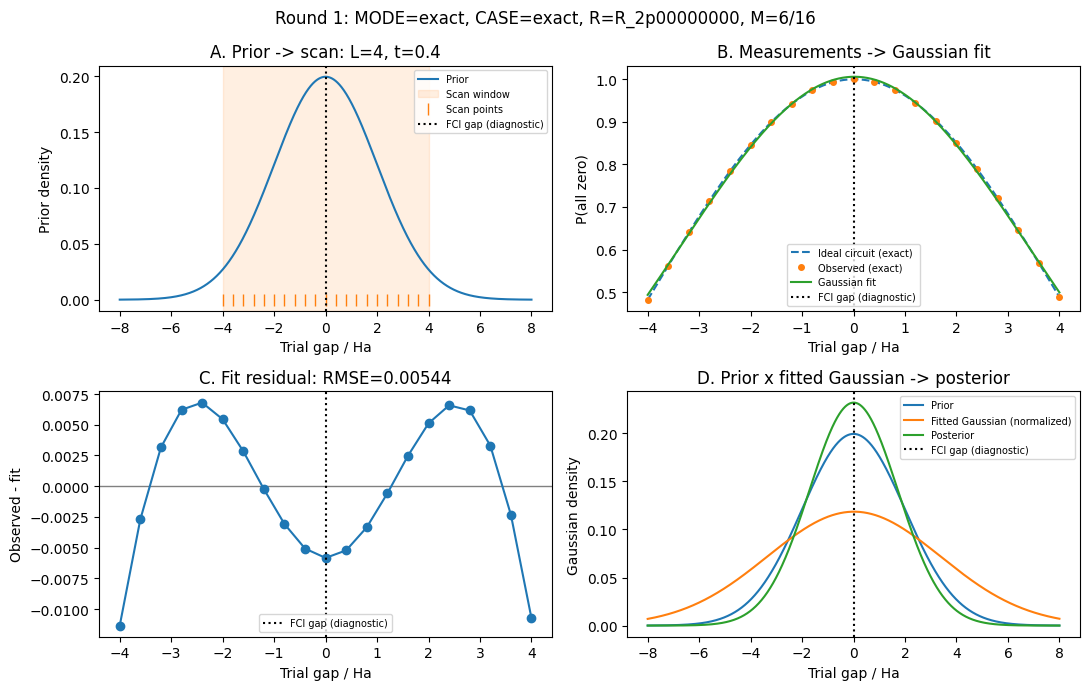

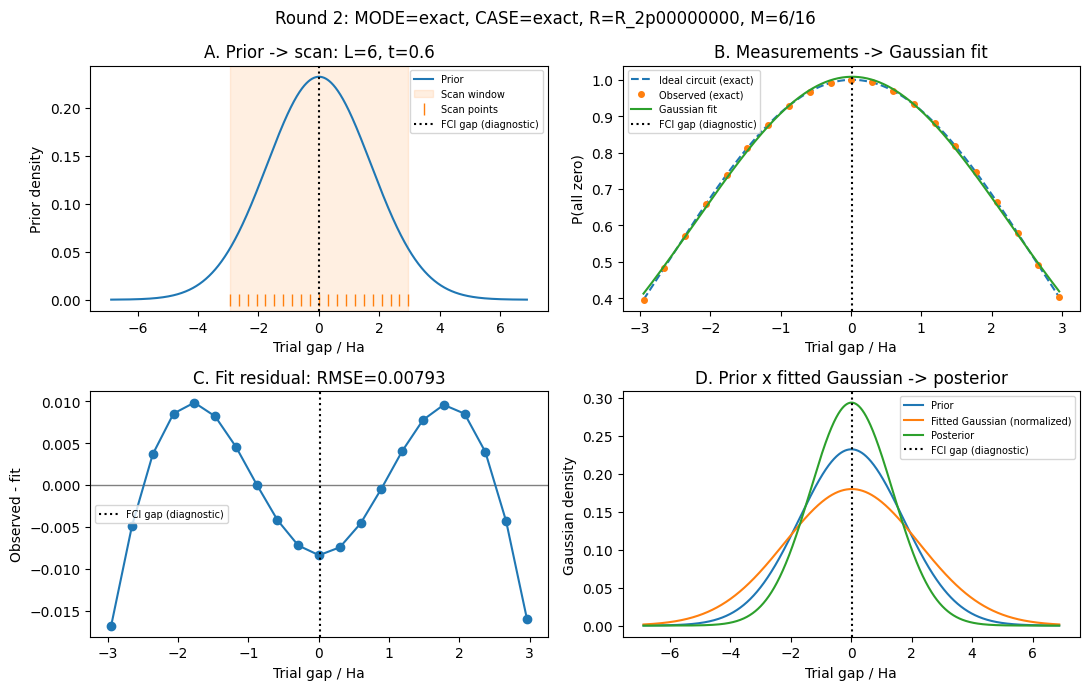

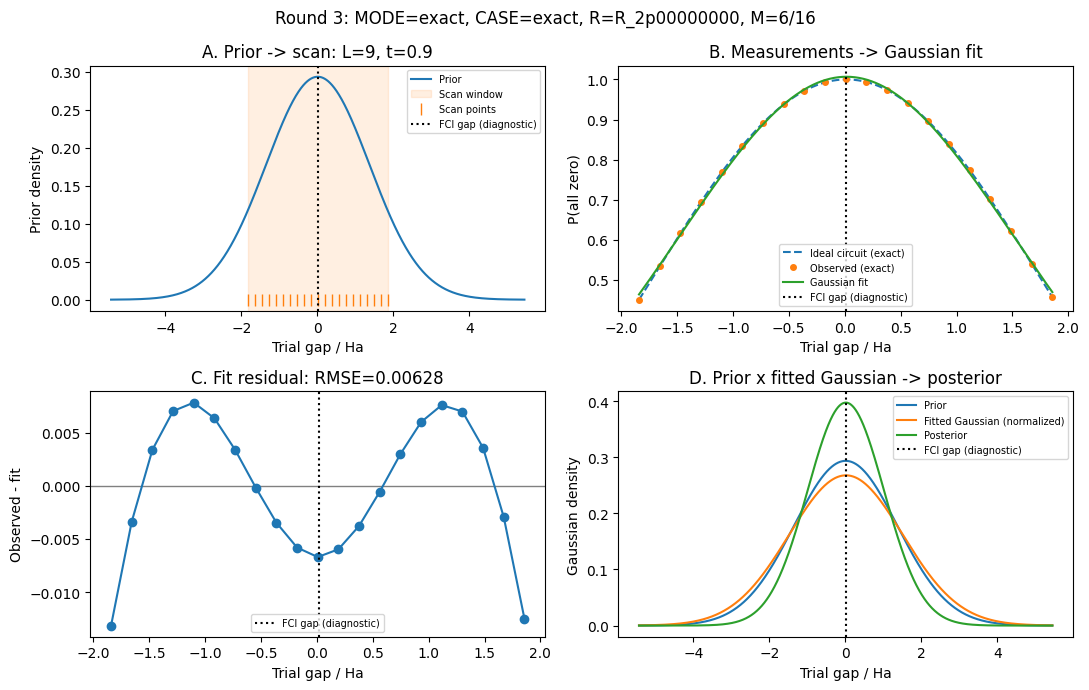

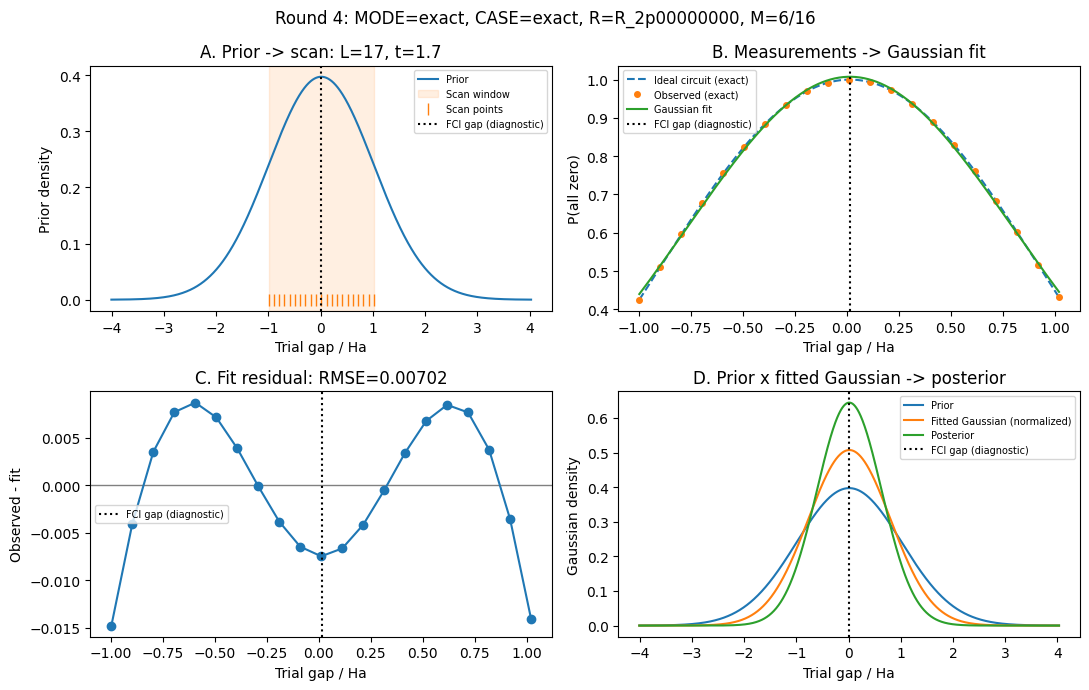

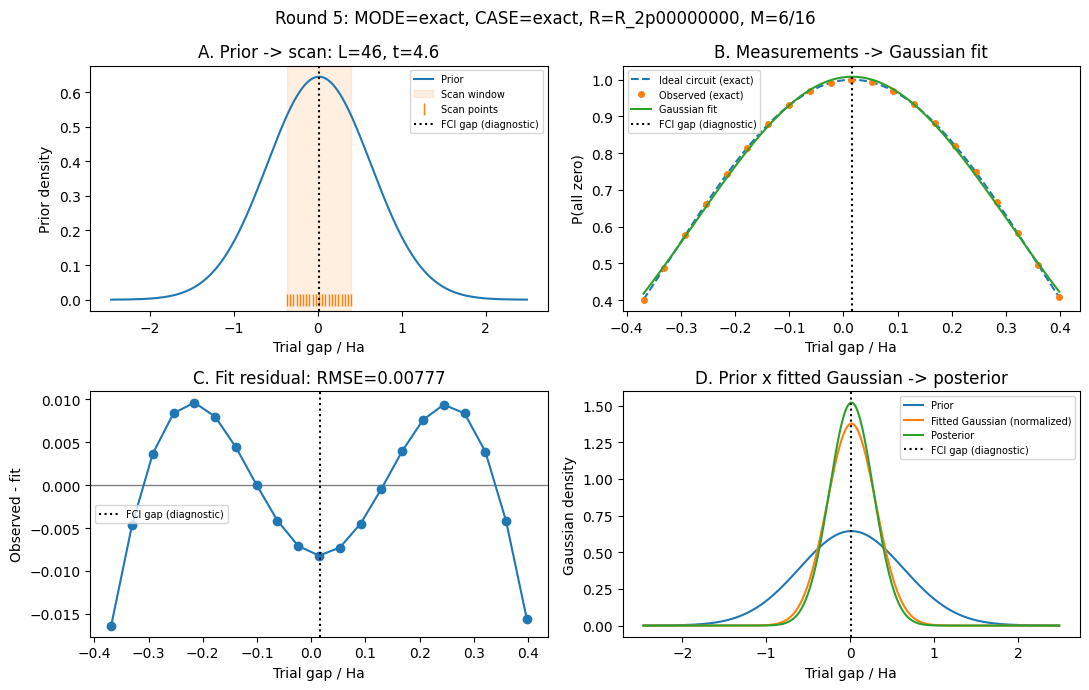

In [12]:
if MEASUREMENT_READY:
    meter=Measurement(MODE,SHOTS,SEED,service,backend,RUN_HARDWARE,MAX_HARDWARE_L)
    history=iterative_bayes(meter,case=CASE,rounds=ROUNDS,initial_mu=INITIAL_MU,
        initial_variance=INITIAL_VARIANCE,points=POINTS,max_L=MAX_L,target_sd=TARGET_SD)
else:
    history=[]
    print('Preview only; no measurement was submitted.')

### 7.1．数値履歴と、幅・誤差・時間の推移

次セルの表は各図と同じ数値です。前行の事後(μ′,v′)と、次行の事前(μ,v)の一致をassertで確認します。
mean±SDは今回のGaussianの平均と幅です。95%信用区間や全誤差保証としては表示していません。
絶対誤差|mean−FCI|とSDを同じ図に描き、「幅が減る」と「真値に近づく」を分けます。
Lと、選択回路の概算CX費用 CX(A)+CX(A†)+L×CX(Uapp)も確認します（既定6/16は516+216L）。実機配置・全体最適化前のブロック直列見積もりです。

r  prior mu    prior v     L     t       fit m        fit w       post mu      post v      RMSE
1   0.000000         4     4    0.40   0.0164355       11.33   0.0042885      2.9563 0.005443
2   0.004289    2.9563     6    0.60   0.0163419      4.9295   0.0088072       1.848 0.007931
3   0.008807     1.848     9    0.90   0.0161537      2.2211   0.0121436      1.0087 0.006279
4   0.012144    1.0087    17    1.70   0.0160415      0.6186   0.0145598     0.38345 0.00702
5   0.014560   0.38345    46    4.60   0.0159553    0.083972   0.0157046    0.068886 0.007773
Posterior -> next prior checked. Source: exact CASE: exact
M6/M16 serial CX estimates: [1380, 1812, 2460, 4188, 10452]


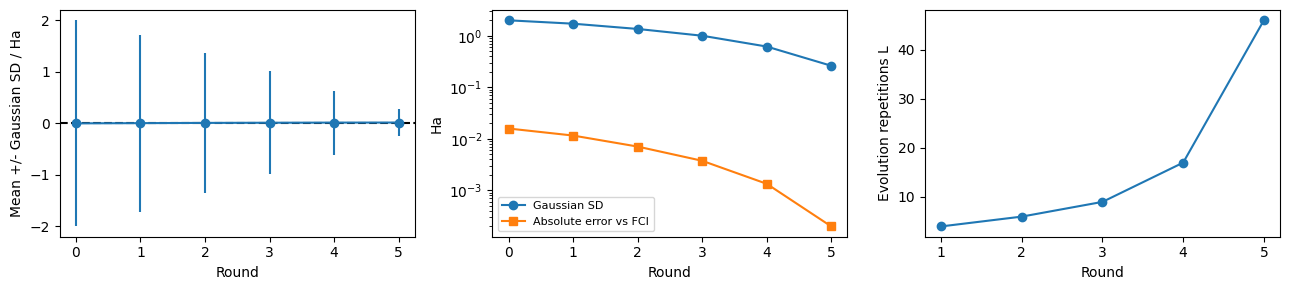

In [13]:
if history:
    print('r  prior mu    prior v     L     t       fit m        fit w       post mu      post v      RMSE')
    for row in history:
        print(f"{row['round']:1d} {row['prior_mu']:10.6f} {row['prior_variance']:9.5g} {row['L']:5d} "
              f"{row['time']:7.2f} {row['fit_mu']:11.7f} {row['fit_variance']:11.5g} "
              f"{row['posterior_mu']:11.7f} {row['posterior_variance']:11.5g} {row['residual_rmse']:.4g}")
    for a,b in zip(history,history[1:]):
        assert a['posterior_mu']==b['prior_mu'] and a['posterior_variance']==b['prior_variance']
    rounds=np.arange(len(history)+1)
    means=np.array([INITIAL_MU]+[row['posterior_mu'] for row in history])
    sd=np.sqrt([INITIAL_VARIANCE]+[row['posterior_variance'] for row in history])
    fig,axes=plt.subplots(1,3,figsize=(13,3))
    axes[0].errorbar(rounds,means,yerr=sd,fmt='o-');axes[0].axhline(GAP,color='black',ls='--')
    axes[0].set(xlabel='Round',ylabel='Mean +/- Gaussian SD / Ha')
    axes[1].semilogy(rounds,sd,'o-',label='Gaussian SD')
    axes[1].semilogy(rounds,np.maximum(abs(means-GAP),1e-15),'s-',label='Absolute error vs FCI')
    axes[1].set(xlabel='Round',ylabel='Ha');axes[1].legend(fontsize=8)
    axes[2].plot(rounds[1:],[row['L'] for row in history],'o-')
    axes[2].set(xlabel='Round',ylabel='Evolution repetitions L')
    plt.tight_layout();plt.show();plt.close(fig)
    print('Posterior -> next prior checked. Source:',MODE,'CASE:',CASE)
    print(f'M{SELECTED_PREP_M}/M{SELECTED_EVOLUTION_M} serial CX estimates:',
          [None if SERIAL_CX['evolution'] is None else SERIAL_CX['preparation']+SERIAL_CX['evolution']*row['L'] for row in history])
else:
    print('No updates. Check preview-only mode, fit failure or iteration limits above.')

### 課題6：ラウンドの図と表を読む

1. 初期事前を固定し、ROUNDSを2→5→8へ増やすと何が変わるか。
2. MODE=shotsでSHOTSやSEEDを変えると、Lの列も変わり得るか。
3. 図Dの事後が狭くても、図Cの残差が大きい場合はどう解釈すべきか。

<details><summary>解答例</summary>

1. 更新を追加します。vが減れば要求Lが大きくなり、L上限に達して指定回数の前に止まる場合があります。
先行ラウンドを同じ設定で再実行した部分は、同じSEEDなら同じ結果です。
2. 測定値が変わるとフィットと事後が変わり、次のLや探索点も変わり得ます。適応的な計画だからです。
3. Gaussianの幅縮小だけを成功とみなせません。曲線モデルやフィットがデータを十分に表しているか、観測の出所・信号・初期条件を確認します。

</details>

## 8．shot noiseを外して、回路近似によるずれを比較する

次の対照は**常にMODE=exactのシミュレーション**です。主実験がibmでも、このセルから実機へ送信しません。
演習4と同じ4条件を同じ初期事前・更新規約で反復し、準備と発展の影響を切り分けます。
主実験のmeter・history・保存ファイルは書き換えません。

CASE=exactでも、有限回数・Gaussian近似・フィット不調による誤差は残り得ます。
CASE=bothでは、元の固有状態でない準備や別の近似ユニタリの位相も影響します。
近似が相殺する場合もあり、「両方近似」が常に「片側だけ近似」より悪いとは限りません。

COMPARE_ROUNDS=8までを試しますが、次のLが上限を超えたらそこまでです。
各CASEで独立に適応するため、途中からL・探索点・実行ラウンド数が異なり得ます。
これは同じ初期条件からの比較で、同じ総発展時間や測定予算を保証する比較ではありません。
固定Lでの純粋な信号比較は演習4を参照してください。

No-shot controls: case / completed rounds / mean / SD / signed error / last residual RMSE
exact 8 0.015905012236419835 0.0018479441731971274 5.4320234432053693e-08 0.008356215287185196
prep_only 7 0.0157828966611009 0.001622180988046778 -0.00012206125508450183 0.022291480470909265
evolution_only 7 0.01784888748264516 0.0018482015074595833 0.001943929566459758 0.008358855959897264
both 7 0.01765154977615241 0.0016293990517883177 0.001746591859967006 0.0248036235389696


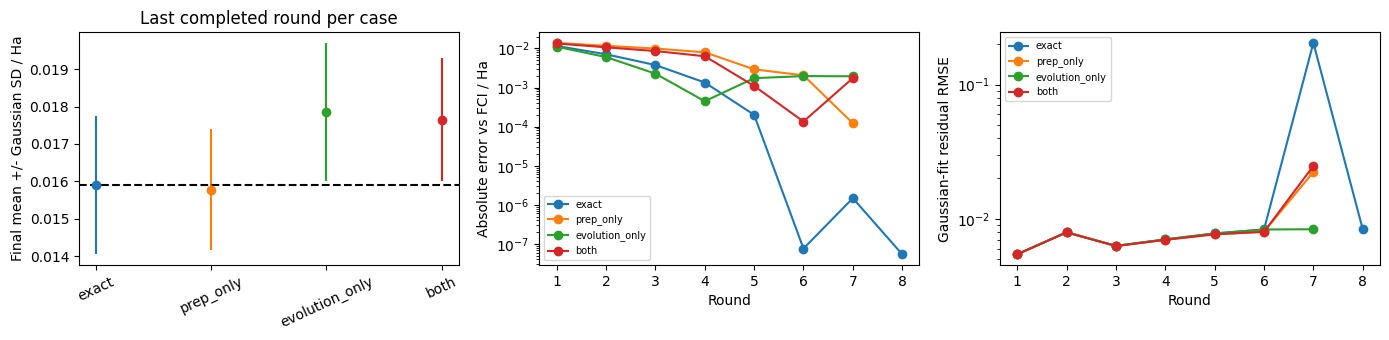

In [14]:
RUN_COMPARISON=True
COMPARE_ROUNDS=8
comparison={};comparison_meters={}
if RUN_COMPARISON:
    for case in ['exact','prep_only','evolution_only','both']:
        control=Measurement('exact',shots=None,seed=SEED)
        rows=iterative_bayes(control,case=case,rounds=COMPARE_ROUNDS,initial_mu=INITIAL_MU,
            initial_variance=INITIAL_VARIANCE,points=POINTS,max_L=MAX_L,
            show_plots=False,output_prefix=None,verbose=False)
        comparison[case]=rows;comparison_meters[case]=control
    print('No-shot controls: case / completed rounds / mean / SD / signed error / last residual RMSE')
    fig,axes=plt.subplots(1,3,figsize=(14,3.5))
    for i,(case,rows) in enumerate(comparison.items()):
        if not rows:continue
        final=rows[-1];sd=np.sqrt(final['posterior_variance'])
        print(case,len(rows),final['posterior_mu'],sd,final['posterior_mu']-GAP,final['residual_rmse'])
        axes[0].errorbar(i,final['posterior_mu'],yerr=sd,fmt='o')
        rr=[row['round'] for row in rows]
        axes[1].semilogy(rr,[max(abs(row['posterior_mu']-GAP),1e-15) for row in rows],'o-',label=case)
        axes[2].semilogy(rr,[max(row['residual_rmse'],1e-15) for row in rows],'o-',label=case)
    axes[0].set_xticks(range(4),list(comparison),rotation=25);axes[0].axhline(GAP,color='black',ls='--')
    axes[0].set(ylabel='Final mean +/- Gaussian SD / Ha',title='Last completed round per case')
    axes[1].set(xlabel='Round',ylabel='Absolute error vs FCI / Ha');axes[1].legend(fontsize=7)
    axes[2].set(xlabel='Round',ylabel='Gaussian-fit residual RMSE');axes[2].legend(fontsize=7)
    plt.tight_layout();plt.show();plt.close(fig)

### 課題7：偏りとGaussian更新の限界

1. MODE=exactで残るずれをshot noiseと説明してよいか。
2. 一つのCASEの残差が急に増えたラウンドで、平均だけを見て収束を主張してよいか。
3. CASE=bothの平均が偶然FCIに近ければ、準備と発展がそれぞれ正確だったといえるか。

<details><summary>解答例</summary>

1. shot noiseは加えていません。回路近似、有限反復、Gaussian近似、フィットの不調を検討します。
特にevolution_onlyの比較は、厳密準備を保ったまま近似発展の位相の影響を調べる対照です。
2. 主張できません。観測曲線とフィットを見て、残差の増加が形の不一致や平坦な局所解などによらないか確認します。
3. いえません。二つの影響が相殺する場合があります。prep_only/evolution_only、演習4の各fidelityと信号も合わせて読みます。

</details>

### 8.1．Mごとの反復推定を比較する

準備M=4・6・8 × 発展M=8・16・32を、**CASE=both・MODE=exact**で比較します。
主実験のMODEがshots/ibmでも、この比較は常にshot noiseなしで、実機へ送信しません。
同じINITIAL_MU・INITIAL_VARIANCE・POINTS・MAX_Lと更新回数から開始します。
各Mの測定結果から独立に次のL・探索点を選ぶため、途中から測定計画や完了回数が異なり得ます。
M_COMPARE_ROUNDSを変更すると比較の更新上限を変えられます。

この比較は現在選んだ構造で実行します。表の「平均−FCI」は、この有限反復の結果の符号付き誤差です。
ここで比較する偏りには回路近似だけでなくGaussian近似・有限反復・フィットの影響も含まれます。
厳密準備・厳密発展の対照も同じ初期条件で計算し、図の破線で示します。
SDはGaussian更新の幅で、全誤差を覆う保証ではありません。L=1のピークずれとも区別します。
比較後は元のMへ戻し、主実験のmeter・history・保存ファイルを保持します。

R_2p00000000: PREP_M=4 (S0/T), EVOLUTION_M=8; serial CX = 348 + 132 L
R_2p00000000: PREP_M=4 (S0/T), EVOLUTION_M=16; serial CX = 348 + 216 L
R_2p00000000: PREP_M=4 (S0/T), EVOLUTION_M=32; serial CX = 348 + 384 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=8; serial CX = 516 + 132 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=32; serial CX = 516 + 384 L
R_2p00000000: PREP_M=8 (S0/T), EVOLUTION_M=8; serial CX = 688 + 132 L
R_2p00000000: PREP_M=8 (S0/T), EVOLUTION_M=16; serial CX = 688 + 216 L
R_2p00000000: PREP_M=8 (S0/T), EVOLUTION_M=32; serial CX = 688 + 384 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L


| 準備M | 発展M | 完了round | 最終L | 最終平均 / Ha | Gaussian SD / Ha | 平均−FCI / Ha | 最終fit RMSE |
|---|---|---|---|---|---|---|---|
| 4 | 8 | 7 | 3490 | 0.00340337 | 0.00413 | -0.01250159 | 0.000914 |
| 4 | 16 | 7 | 9817 | 0.03712515 | 0.00142 | +0.02122019 | 0.00477 |
| 4 | 32 | 7 | 9793 | 0.03487587 | 0.00135 | +0.01897091 | 0.00526 |
| 6 | 8 | 7 | 5954 | 0.01563501 | 0.00183 | -0.00026994 | 0.0164 |
| 6 | 16 | 7 | 7188 | 0.01765155 | 0.00163 | +0.00174659 | 0.0248 |
| 6 | 32 | 7 | 7188 | 0.01576261 | 0.00162 | -0.00014235 | 0.0221 |
| 8 | 8 | 7 | 7392 | 0.00649433 | 0.00172 | -0.00941063 | 0.0175 |
| 8 | 16 | 7 | 7191 | 0.01784902 | 0.00185 | +0.00194406 | 0.00835 |
| 8 | 32 | 7 | 7191 | 0.01588962 | 0.00185 | -0.00001534 | 0.00835 |

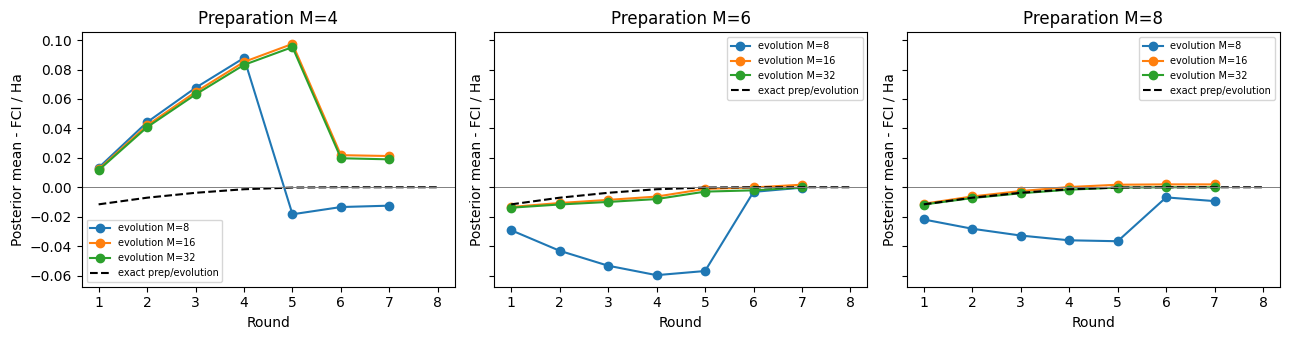

In [15]:
from IPython.display import Markdown, display
M_COMPARE_ROUNDS=8

def compare_saved_m_bayes():
    selected=(SELECTED_PREP_M,SELECTED_EVOLUTION_M)
    results={}
    kwargs=dict(rounds=M_COMPARE_ROUNDS,initial_mu=INITIAL_MU,initial_variance=INITIAL_VARIANCE,
                points=POINTS,max_L=MAX_L,show_plots=False,output_prefix=None,verbose=False)
    reference=iterative_bayes(Measurement('exact',shots=None),case='exact',**kwargs)
    try:
        for pm in AVAILABLE_PREP_M:
            for em in AVAILABLE_EVOLUTION_M:
                select_circuits(pm,em)
                results[(pm,em)]=iterative_bayes(Measurement('exact',shots=None),case='both',**kwargs)
    finally:
        select_circuits(*selected)
    return results,reference

M_BAYES_COMPARISON,M_BAYES_REFERENCE=compare_saved_m_bayes()
header='| 準備M | 発展M | 完了round | 最終L | 最終平均 / Ha | Gaussian SD / Ha | 平均−FCI / Ha | 最終fit RMSE |\n|---|---|---|---|---|---|---|---|'
lines=[]
for (pm,em),rows in M_BAYES_COMPARISON.items():
    if not rows:
        lines.append(f'| {pm} | {em} | 0 | — | — | — | — | — |')
        continue
    r=rows[-1]
    lines.append(f"| {pm} | {em} | {len(rows)} | {r['L']} | {r['posterior_mu']:.8f} | {np.sqrt(r['posterior_variance']):.3g} | {r['posterior_mu']-GAP:+.8f} | {r['residual_rmse']:.3g} |")
display(Markdown(header+'\n'+'\n'.join(lines)))
fig,axes=plt.subplots(1,3,figsize=(13,3.5),sharey=True)
for ax,pm in zip(axes,AVAILABLE_PREP_M):
    for em in AVAILABLE_EVOLUTION_M:
        rows=M_BAYES_COMPARISON[(pm,em)]
        ax.plot([r['round'] for r in rows],[r['posterior_mu']-GAP for r in rows],
                'o-',label=f'evolution M={em}')
    ax.plot([r['round'] for r in M_BAYES_REFERENCE],
            [r['posterior_mu']-GAP for r in M_BAYES_REFERENCE],'k--',label='exact prep/evolution')
    ax.axhline(0,color='gray',lw=.7)
    ax.set(title=f'Preparation M={pm}',xlabel='Round',ylabel='Posterior mean - FCI / Ha')
    ax.legend(fontsize=7)
plt.tight_layout();plt.show();plt.close(fig)

### 課題7補足：Mを増やした推定を評価する

最終SDが最小のMを、最も偏りが小さいMとみなしてよいか。
また、同じroundの各点は同じL・同じ測定予算での比較か。

<details><summary>解答例</summary>

どちらもいえません。SDは近似Gaussian更新の幅であり、FCIからのずれは表と図の符号付き誤差で別に比較します。
厳密回路の破線にも有限反復やGaussianフィット由来のずれが残り得ます。
各Mが測定結果に応じてLと探索点を選ぶため、同じroundでもL・回路費用は揃いません。
上限によって完了round数が異なる場合は最終値の単純な順位付けも避け、共通のroundと各L・残差を確認します。
固定LでMの信号を比較する対照は演習4の表と図です。

</details>

## 9．実機で反復するときの操作と、保存結果の読み方

1ラウンドごとにPOINTS本を1ジョブで送り、countsを取得・フィットしてから次の条件を決めます。
実機の待ち時間やノイズがあるため、シミュレーションと同じL列になるとは限りません。

- RUN_HARDWARE=Falseはプレビューのみです。段階実行も反復測定もスキップします。
- 送信直後に`outputs/ibm_jobs/`へジョブIDを保存します。同じ条件なら再投入せず回収します。
- 手順を最初からやり直すときも、保存先と条件が同じなら初回から再利用し、計画を再計算します。
- 新しい独立測定が必要なら、元の記録を保持したまま`Measurement(directory=...)`へ別の保存先を渡します。
- 主実験の履歴は`outputs/exercise5_updates.json`、測定値は`outputs/exercise5_measurements.json`です。
- MAX_HARDWARE_Lを超えるラウンドは送信前に止まり、そこまでの事後を残します。次のLは`hardware_preview`で費用を確認します。

フィット失敗時は観測を保存し、不適切な事後を追加せずに終了します。
残差が大きい場合は自動的に正解へ補正しません。SDだけでなく曲線とデータの出所を確認してください。
Colabでは切断に備え、ジョブ記録をDrive等へ保存します。記録を失うと自動再利用ができません。
本教材の検証ではIBM実機へ送信していません。

### 課題8：反復実験の結果を説明する

事前・測定条件・counts/確率・フィット・事後・次の計画を、保存履歴と図で対応させて説明してください。
同時に、表示SDを何の保証として扱ってはいけないか述べてください。

### 解答例（課題8：全体の振り返り）

事前のμ,vからt_req・L・探索点を選び、全0確率または全shotsに対する頻度を得ます。
その曲線のGaussianフィットから中心mと幅²wを求め、事前との積でμ′,v′を更新し、次の事前へ渡します。
図Aが計画、B/Cが測定とフィット、Dが積更新です。表では前行の事後と次行の事前が一致します。
表示SDはこのGaussian近似更新の幅であり、二項尤度の厳密な事後幅や、回路近似・実機ノイズを含む全誤差の保証ではありません。


In [16]:
# 同じ回路の行列確率と、全9 qubit状態ベクトルの全0確率を照合。
for eps in [GAP, GAP+.25]:
    actual=Statevector.from_instruction(experiment_circuit(1,eps)).probabilities()[0]
    np.testing.assert_allclose(actual,probability('both',1,eps),atol=1e-10)
np.testing.assert_allclose(probability('exact',3,np.array([GAP,GAP+.1])),
    (1+np.cos(np.array([0,.1])*3*DT))/2,atol=1e-10)
assert GAP>0
np.testing.assert_allclose(GAP,float(MODEL['energy_T']-MODEL['energy_S0']),atol=1e-12)
print('Circuit / amplitude / exact cosine checks passed')

Circuit / amplitude / exact cosine checks passed


### 出所と再現範囲

[Kanno et al., PNAS (2025)](https://doi.org/10.1073/pnas.2425026122)と、
[固定コミットの著者コード](https://github.com/sk888ks/TQPDE_open/blob/9cd88464c5c50dda783150661813609092d7f2b6/src/QPDE_Bayes_session_MPSBWMPO_RD.py)のGaussianフィット・更新を参照します。
本冊はH₄と選択した保存回路を用いた説明用の計算で、論文の分子・実機実験全体の再現ではありません。